# Credit Card Default Prediction: A Random Forest Case Study

**Problem statement:** A bank's credit-risk team needs to identify which
cardholders are likely to default on their payment next month, so collection
and credit-limit decisions can be made proactively rather than reactively.
This notebook uses 30,000 Taiwanese credit card accounts (demographics,
credit limit, six months of repayment history, billing, and payment amounts)
to build and compare four classification approaches: Logistic Regression,
K-Nearest Neighbors, a Decision Tree, and a Random Forest.

**The deliberate structure of this notebook**: a genuinely untouched
baseline is built first (no cleaning, scaling, encoding, or imbalance
handling at all) before any exploratory analysis, so the rest of the
notebook has a real "before" to compare against. Every later stage —
full EDA, imbalance handling, and hyperparameter tuning — is then measured
against that same baseline and against each other, on the exact same
held-out rows throughout.

**How AI is used in this notebook:** after each major analytical stage, a
short narrative insight is generated by Google's Gemini model, grounded in
the actual computed numbers for that stage. The API key is never hardcoded;
it is loaded from a local, gitignored `.env` file.

# 1 · Imports & Configuration

Load the core stack: **pandas**/**NumPy** for tabular and numerical work,
**Matplotlib** for figure-level plot control, **Seaborn** (the only charting
library used for visualizations) for statistical graphics, **SciPy** and
**statsmodels** for the VIF multicollinearity diagnostic, **imbalanced-learn**
for SMOTE, and **scikit-learn** for every model, the shared preprocessing
pipeline, and GridSearchCV. `PYTHONWARNINGS` is set before importing
anything else so the warning-suppression also reaches the parallel worker
processes `GridSearchCV(n_jobs=-1)` spawns, not just the main process.

In [1]:
import os
os.environ["PYTHONWARNINGS"] = "ignore"

import re
import logging
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.tools.tools import add_constant
from sklearn.model_selection import train_test_split, GridSearchCV, KFold
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, classification_report, roc_auc_score, roc_curve,
    confusion_matrix, ConfusionMatrixDisplay,
)
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline
from IPython.display import Markdown, display

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", palette="deep", font_scale=1.0)
plt.rcParams["figure.dpi"] = 110
plt.rcParams["axes.titleweight"] = "bold"
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")

RANDOM_STATE = 42
TARGET = "defaulted"
OVERFIT_THRESHOLD_PCT = 10.0

# 2 · Secure AI Setup (Gemini via Google AI Studio)

Google's **Gemini** model is called once per major analytical stage to turn
computed metrics into decision-ready narrative insight. The key is loaded at
runtime from a local `.env` file (`Random_Forest_case_study/.env`, listed in
`.gitignore`) using `python-dotenv`, never hardcoded. `generate_insight()`
walks down a chain of fallback models on any failure, and only falls back to
a plain text summary if every model in the chain is exhausted or the key is
missing. The `google_genai.types` logger is raised to `ERROR` immediately,
since some Gemini models return an internal "thinking" trace alongside the
answer and the SDK otherwise logs a visible (but harmless) warning about
dropping it on every single call.

In [2]:
from dotenv import load_dotenv
from google import genai

load_dotenv(Path.cwd() / ".env")
logging.getLogger("google_genai.types").setLevel(logging.ERROR)

GOOGLE_API_KEY = os.getenv("GOOGLE_API_KEY")
GEMINI_MODEL_CHAIN = [
    model.strip()
    for model in os.getenv(
        "GEMINI_MODEL", "gemini-3.6-flash,gemini-3.5-flash-lite,gemini-flash-lite-latest,gemini-2.0-flash-lite"
    ).split(",")
]
_client = genai.Client(api_key=GOOGLE_API_KEY) if GOOGLE_API_KEY else None

def generate_insight(analysis_topic, data_summary):
    fallback = (
        "**AI narrative unavailable**: set `GOOGLE_API_KEY` in `.env` to enable Gemini-generated "
        "insights. Review the computed metrics and chart above directly.\n\n"
        f"Computed summary:\n\n{data_summary}"
    )
    if _client is None:
        return fallback
    prompt = (
        "You are a senior credit-risk data analyst presenting findings to a bank's risk "
        "management team.\n"
        f"Analysis topic: {analysis_topic}\n\n"
        f"Computed data summary:\n{data_summary}\n\n"
        "Write a concise, decision-ready insight (3-5 sentences) followed by 2-4 bullet-point "
        "recommendations, in markdown. Reference the specific numbers given. Do not restate the "
        "raw numbers as a table; weave them into the narrative. Use clear, well-punctuated "
        "sentences (commas, periods, colons, semicolons, and parentheses only). Do not use "
        "em dashes anywhere in the response."
    )
    last_error = None
    for model_name in GEMINI_MODEL_CHAIN:
        try:
            response = _client.models.generate_content(model=model_name, contents=prompt)
            return response.text
        except Exception as exc:
            last_error = exc
            continue
    return fallback + f"\n\n_(Gemini call failed on all models in the fallback chain: {last_error})_"

# 3 · Data Dictionary

This dataset ships with no separate description file, so the column meanings
below are the well-known UCI "Default of Credit Card Clients" documentation
(Taiwan, 2005), stated here as verified domain knowledge rather than
guessed.

| Column | Meaning |
|---|---|
| `ID` | Row identifier, 1..30000, all unique. Not a feature. |
| `LIMIT_BAL` | Amount of given credit (NT dollar), continuous. |
| `SEX` | `1` = male, `2` = female. |
| `EDUCATION` | Documented: `1` graduate school, `2` university, `3` high school, `4` others. Undocumented but observed: `0`, `5`, `6` — a known quirk of this dataset. |
| `MARRIAGE` | Documented: `1` married, `2` single, `3` others. Undocumented but observed: `0`. |
| `AGE` | In years. |
| `PAY_0, PAY_2..PAY_6` | Repayment status for September (`PAY_0`), August (`PAY_2`), July (`PAY_3`), June (`PAY_4`), May (`PAY_5`), April (`PAY_6`) 2005. There is no `PAY_1` — the most recent month is named `PAY_0`, a known naming oddity, not a missing column. Values: `-2` no consumption, `-1` paid duly, `0` revolving credit not yet due, `1`-`8`+ months delayed. Genuinely **ordinal** (more negative/zero is better repayment behavior). |
| `BILL_AMT1..BILL_AMT6` | Bill statement amount for the same six months. Expected to be **highly collinear** with each other (consecutive months of the same underlying balance). |
| `PAY_AMT1..PAY_AMT6` | Amount actually paid in each of the same six months. |
| `defaulted` | **Target.** `1` = defaulted on payment next month, `0` = did not. |

# 4 · Loading & Dropping the Identifier Column

Load the single source file and drop `ID` immediately. This is not an EDA
step being smuggled in early: a row identifier is not a modeling decision
the way skipping cleaning, scaling, encoding, or imbalance handling is — it
is recognized from the start as a structural non-feature, the same way no
one would feed a literal row index into a model. Nothing else is touched
yet: no null check, no duplicate check, no distribution analysis, no
correlation, no outlier treatment, no scaling, no encoding, no imbalance
handling. That is all deliberately deferred to the full EDA phase, so the
baseline models that follow are a genuine "zero preprocessing" reference
point.

In [3]:
DATA_PATH = Path("../Datasets/RF_Credit_card_defaulter_dataset/Credit Card Default Data.csv")
df_raw = pd.read_csv(DATA_PATH)
print(f"Raw shape: {df_raw.shape}")
df_raw.head()

Raw shape: (30000, 25)


,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,PAY_5,PAY_6,BILL_AMT1,BILL_AMT2,BILL_AMT3,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,defaulted
0,1,20000,2,2,1,24,2,2,-1,-1,-2,-2,3913,3102,689,0,0,0,0,689,0,0,0,0,1
1,2,120000,2,2,2,26,-1,2,0,0,0,2,2682,1725,2682,3272,3455,3261,0,1000,1000,1000,0,2000,1
2,3,90000,2,2,2,34,0,0,0,0,0,0,29239,14027,13559,14331,14948,15549,1518,1500,1000,1000,1000,5000,0
3,4,50000,2,2,1,37,0,0,0,0,0,0,46990,48233,49291,28314,28959,29547,2000,2019,1200,1100,1069,1000,0
4,5,50000,1,2,1,57,-1,0,-1,0,0,0,8617,5670,35835,20940,19146,19131,2000,36681,10000,9000,689,679,0


In [4]:
df = df_raw.drop(columns=["ID"])
print(f"Shape after dropping ID: {df.shape}")
df.head()

Shape after dropping ID: (30000, 24)


,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,PAY_5,PAY_6,BILL_AMT1,BILL_AMT2,BILL_AMT3,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,defaulted
0,20000,2,2,1,24,2,2,-1,-1,-2,-2,3913,3102,689,0,0,0,0,689,0,0,0,0,1
1,120000,2,2,2,26,-1,2,0,0,0,2,2682,1725,2682,3272,3455,3261,0,1000,1000,1000,0,2000,1
2,90000,2,2,2,34,0,0,0,0,0,0,29239,14027,13559,14331,14948,15549,1518,1500,1000,1000,1000,5000,0
3,50000,2,2,1,37,0,0,0,0,0,0,46990,48233,49291,28314,28959,29547,2000,2019,1200,1100,1069,1000,0
4,50000,1,2,1,57,-1,0,-1,0,0,0,8617,5670,35835,20940,19146,19131,2000,36681,10000,9000,689,679,0


# 5 · Train / Validation / Test Split (60/20/20)

One stratified 60/20/20 split, done once here, reused for every later
section: 60% train, 20% validation, 20% test. Stratifying on the target
keeps the same ~78/22 class balance in every split. The baseline models
below use this exact split on the untouched data; every later phase reuses
the same row-level split (just on a cleaned/encoded feature representation),
so every comparison across stages is on identical rows.

In [5]:
X_full = df.drop(columns=[TARGET])
y_full = df[TARGET]

X_train_raw, X_temp_raw, y_train, y_temp = train_test_split(
    X_full, y_full, test_size=0.4, stratify=y_full, random_state=RANDOM_STATE
)
X_val_raw, X_test_raw, y_val, y_test = train_test_split(
    X_temp_raw, y_temp, test_size=0.5, stratify=y_temp, random_state=RANDOM_STATE
)

print(f"Train: {X_train_raw.shape} ({len(X_train_raw) / len(X_full):.0%})")
print(f"Validation: {X_val_raw.shape} ({len(X_val_raw) / len(X_full):.0%})")
print(f"Test: {X_test_raw.shape} ({len(X_test_raw) / len(X_full):.0%})")
print()
print("Target distribution (train):")
print(y_train.value_counts(normalize=True))

Train: (18000, 23) (60%)
Validation: (6000, 23) (20%)
Test: (6000, 23) (20%)

Target distribution (train):
defaulted
0   0.779
1   0.221
Name: proportion, dtype: float64


# 6 · Baseline Models (No EDA, No Scaling, No Encoding, No Imbalance Handling)

Four model families are fit directly on the untouched train split: Logistic
Regression, K-Nearest Neighbors, a Decision Tree, and a Random Forest, all
with library defaults. A single shared evaluation toolkit is defined once
here and reused for every model at every stage of this notebook, so every
comparison table that follows has identical columns and nothing is computed
ad hoc per cell.

In [6]:
def evaluate(fitted_model, X, y):
    predictions = fitted_model.predict(X)
    probabilities = fitted_model.predict_proba(X)[:, 1] if hasattr(fitted_model, "predict_proba") else None
    report = classification_report(y, predictions, output_dict=True, zero_division=0)
    return {
        "accuracy": accuracy_score(y, predictions),
        "auc": roc_auc_score(y, probabilities) if probabilities is not None else np.nan,
        "precision_macro": report["macro avg"]["precision"],
        "recall_macro": report["macro avg"]["recall"],
        "f1_macro": report["macro avg"]["f1-score"],
        "precision_default": report["1"]["precision"],
        "recall_default": report["1"]["recall"],
        "f1_default": report["1"]["f1-score"],
        "probabilities": probabilities,
        "predictions": predictions,
    }

def overfit_gap(train_metrics, test_metrics, key="accuracy", threshold=OVERFIT_THRESHOLD_PCT):
    gap_pct = abs(train_metrics[key] - test_metrics[key]) / abs(train_metrics[key]) * 100
    if gap_pct > threshold:
        verdict = "OVERFIT" if train_metrics[key] > test_metrics[key] else "UNDERFIT"
    else:
        verdict = "OK"
    return gap_pct, verdict

def comparison_row(stage, model_label, train_metrics, test_metrics, gap_pct, verdict, extra=None):
    row = {
        "stage": stage, "model": model_label,
        "train_accuracy": train_metrics["accuracy"], "test_accuracy": test_metrics["accuracy"],
        "test_auc": test_metrics["auc"],
        "test_precision_default": test_metrics["precision_default"],
        "test_recall_default": test_metrics["recall_default"],
        "test_f1_default": test_metrics["f1_default"],
        "test_f1_macro": test_metrics["f1_macro"],
        "overfit_gap_pct": gap_pct, "verdict": verdict,
    }
    if extra:
        row.update(extra)
    return row

def print_full_report(name, test_metrics, y, train_metrics=None, gap_pct=None, verdict=None):
    print(f"--- {name}: classification report (test) ---")
    print(classification_report(y, test_metrics["predictions"], zero_division=0))
    print(f"Test accuracy: {test_metrics['accuracy']:.4f} | Test ROC-AUC: {test_metrics['auc']:.4f}")
    if train_metrics is not None:
        print(f"Train accuracy: {train_metrics['accuracy']:.4f} | Train/test gap: {gap_pct:.2f}% -> {verdict}")

    cm = confusion_matrix(y, test_metrics["predictions"])
    fig, ax = plt.subplots(figsize=(4.5, 4))
    ConfusionMatrixDisplay(cm, display_labels=["No Default", "Default"]).plot(ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(f"{name}: Confusion Matrix (Test)")
    plt.tight_layout()
    plt.show()

def plot_roc_overlay(fitted_models, X_by_model, y, title):
    fig, ax = plt.subplots(figsize=(7, 6))
    for label, model in fitted_models.items():
        X_for_model = X_by_model[label]
        proba = model.predict_proba(X_for_model)[:, 1]
        fpr, tpr, _ = roc_curve(y, proba)
        auc = roc_auc_score(y, proba)
        ax.plot(fpr, tpr, label=f"{label} (AUC={auc:.3f})")
    ax.plot([0, 1], [0, 1], linestyle="--", color="grey", label="Random (AUC=0.500)")
    ax.set_xlabel("False Positive Rate")
    ax.set_ylabel("True Positive Rate")
    ax.set_title(title)
    ax.legend(loc="lower right", fontsize=9)
    plt.tight_layout()
    plt.show()

def plot_stage_comparison(stage_df, title_suffix):
    metrics_long = stage_df.melt(
        id_vars="model", value_vars=["train_accuracy", "test_accuracy", "test_f1_macro", "test_auc"],
        var_name="metric", value_name="value",
    )
    fig, ax = plt.subplots(figsize=(11, 5))
    sns.barplot(data=metrics_long, x="model", y="value", hue="metric", ax=ax)
    ax.set_title(f"Model Comparison: {title_suffix}")
    ax.set_ylim(0, 1.0)
    ax.set_xlabel("")
    plt.xticks(rotation=15, ha="right")
    plt.tight_layout()
    plt.show()

model_comparison_rows = []

## 6.1 · Logistic Regression (Baseline)

--- Baseline Logistic Regression: classification report (test) ---
              precision    recall  f1-score   support

           0       0.83      0.96      0.89      4673
           1       0.68      0.29      0.41      1327

    accuracy                           0.81      6000
   macro avg       0.75      0.63      0.65      6000
weighted avg       0.79      0.81      0.78      6000

Test accuracy: 0.8125 | Test ROC-AUC: 0.7146
Train accuracy: 0.8121 | Train/test gap: 0.05% -> OK


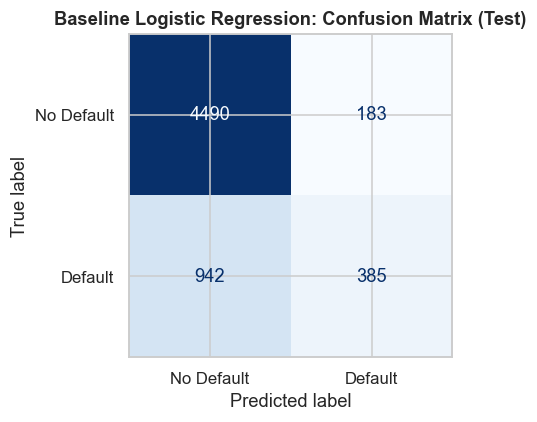

In [7]:
baseline_logistic = LogisticRegression(max_iter=1000)
baseline_logistic.fit(X_train_raw, y_train)

baseline_logistic_train = evaluate(baseline_logistic, X_train_raw, y_train)
baseline_logistic_test = evaluate(baseline_logistic, X_test_raw, y_test)
baseline_logistic_gap, baseline_logistic_verdict = overfit_gap(baseline_logistic_train, baseline_logistic_test)
print_full_report("Baseline Logistic Regression", baseline_logistic_test, y_test, baseline_logistic_train, baseline_logistic_gap, baseline_logistic_verdict)
model_comparison_rows.append(comparison_row("Baseline", "Logistic Regression", baseline_logistic_train, baseline_logistic_test, baseline_logistic_gap, baseline_logistic_verdict))

## 6.2 · K-Nearest Neighbors (Baseline)

KNN is a distance-based model: with no scaling applied yet, columns like
`BILL_AMT1` (ranging into the tens of thousands) will dominate the Euclidean
distance calculation over columns like `SEX` (coded 1/2), regardless of
which is actually more predictive. This is expected to show up as weaker
performance here than Logistic Regression, purely from the missing scaling
step, not from the algorithm itself being worse.

--- Baseline KNN: classification report (test) ---
              precision    recall  f1-score   support

           0       0.80      0.92      0.86      4673
           1       0.38      0.17      0.23      1327

    accuracy                           0.76      6000
   macro avg       0.59      0.55      0.54      6000
weighted avg       0.71      0.76      0.72      6000

Test accuracy: 0.7563 | Test ROC-AUC: 0.6081
Train accuracy: 0.8133 | Train/test gap: 7.00% -> OK


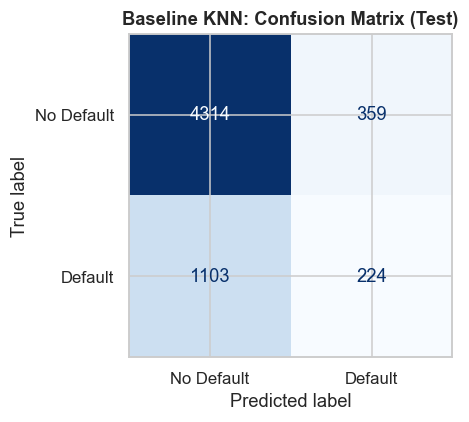

In [8]:
baseline_knn = KNeighborsClassifier()
baseline_knn.fit(X_train_raw, y_train)

baseline_knn_train = evaluate(baseline_knn, X_train_raw, y_train)
baseline_knn_test = evaluate(baseline_knn, X_test_raw, y_test)
baseline_knn_gap, baseline_knn_verdict = overfit_gap(baseline_knn_train, baseline_knn_test)
print_full_report("Baseline KNN", baseline_knn_test, y_test, baseline_knn_train, baseline_knn_gap, baseline_knn_verdict)
model_comparison_rows.append(comparison_row("Baseline", "KNN", baseline_knn_train, baseline_knn_test, baseline_knn_gap, baseline_knn_verdict, {"k_value": baseline_knn.n_neighbors}))

## 6.3 · Decision Tree (Baseline)

An unpruned Decision Tree (no `max_depth`, no `ccp_alpha`) will keep
splitting until its leaves are pure, which almost always means memorizing
the training set rather than learning a generalizable pattern. Expect a
near-perfect training score here alongside a much weaker test score, the
clearest possible illustration of overfitting before any pruning is applied.

--- Baseline Decision Tree: classification report (test) ---
              precision    recall  f1-score   support

           0       0.83      0.82      0.82      4673
           1       0.39      0.42      0.40      1327

    accuracy                           0.73      6000
   macro avg       0.61      0.62      0.61      6000
weighted avg       0.73      0.73      0.73      6000

Test accuracy: 0.7272 | Test ROC-AUC: 0.6162
Train accuracy: 0.9994 | Train/test gap: 27.24% -> OVERFIT


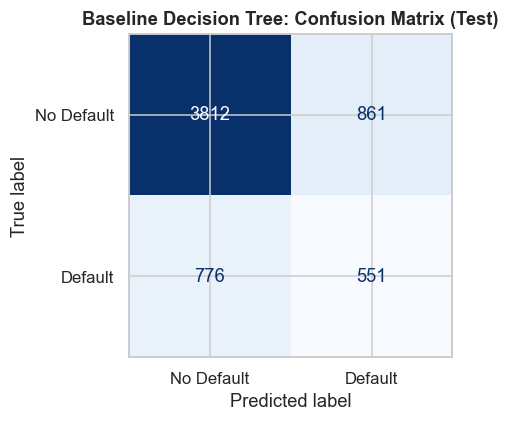

In [9]:
baseline_tree = DecisionTreeClassifier(random_state=RANDOM_STATE)
baseline_tree.fit(X_train_raw, y_train)

baseline_tree_train = evaluate(baseline_tree, X_train_raw, y_train)
baseline_tree_test = evaluate(baseline_tree, X_test_raw, y_test)
baseline_tree_gap, baseline_tree_verdict = overfit_gap(baseline_tree_train, baseline_tree_test)
print_full_report("Baseline Decision Tree", baseline_tree_test, y_test, baseline_tree_train, baseline_tree_gap, baseline_tree_verdict)
model_comparison_rows.append(comparison_row("Baseline", "Decision Tree", baseline_tree_train, baseline_tree_test, baseline_tree_gap, baseline_tree_verdict))

## 6.4 · Random Forest (Baseline)

A Random Forest averages many such unpruned trees over bootstrapped samples
and random feature subsets, which should recover a meaningfully better test
score than the single Decision Tree even with no tuning at all — but with
default (unlimited) tree depth, the forest is still expected to show some
overfitting of its own.

--- Baseline Random Forest: classification report (test) ---
              precision    recall  f1-score   support

           0       0.84      0.94      0.89      4673
           1       0.65      0.37      0.47      1327

    accuracy                           0.82      6000
   macro avg       0.74      0.66      0.68      6000
weighted avg       0.80      0.82      0.80      6000

Test accuracy: 0.8162 | Test ROC-AUC: 0.7641
Train accuracy: 0.9994 | Train/test gap: 18.33% -> OVERFIT


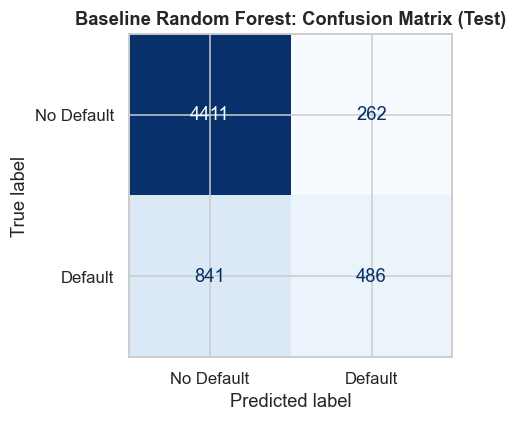

OOB score: 0.8168


In [10]:
baseline_forest = RandomForestClassifier(random_state=RANDOM_STATE, oob_score=True, bootstrap=True)
baseline_forest.fit(X_train_raw, y_train)

baseline_forest_train = evaluate(baseline_forest, X_train_raw, y_train)
baseline_forest_test = evaluate(baseline_forest, X_test_raw, y_test)
baseline_forest_gap, baseline_forest_verdict = overfit_gap(baseline_forest_train, baseline_forest_test)
print_full_report("Baseline Random Forest", baseline_forest_test, y_test, baseline_forest_train, baseline_forest_gap, baseline_forest_verdict)
print(f"OOB score: {baseline_forest.oob_score_:.4f}")
model_comparison_rows.append(comparison_row("Baseline", "Random Forest", baseline_forest_train, baseline_forest_test, baseline_forest_gap, baseline_forest_verdict, {"oob_score": baseline_forest.oob_score_}))

## 6.5 · Baseline Comparison: Table & Visualization

All four baseline models side by side, before moving on to any cleaning,
scaling, encoding, or imbalance handling — this table is the "before"
picture the rest of the notebook will be measured against.

In [11]:
baseline_comparison = pd.DataFrame(model_comparison_rows)
display(baseline_comparison[[
    "model", "train_accuracy", "test_accuracy", "test_auc",
    "test_precision_default", "test_recall_default", "test_f1_default",
    "overfit_gap_pct", "verdict",
]])

,model,train_accuracy,test_accuracy,test_auc,test_precision_default,test_recall_default,test_f1_default,overfit_gap_pct,verdict
0,Logistic Regression,0.812,0.812,0.715,0.678,0.290,0.406,0.055,OK
1,KNN,0.813,0.756,0.608,0.384,0.169,0.235,7.002,OK
2,Decision Tree,0.999,0.727,0.616,0.390,0.415,0.402,27.243,OVERFIT
3,Random Forest,0.999,0.816,0.764,0.650,0.366,0.468,18.333,OVERFIT


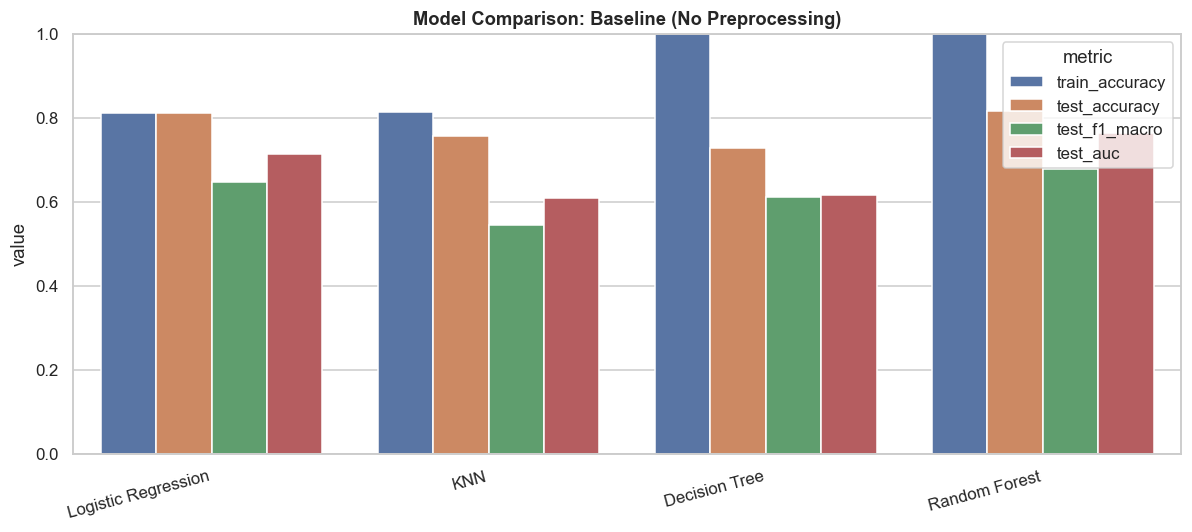

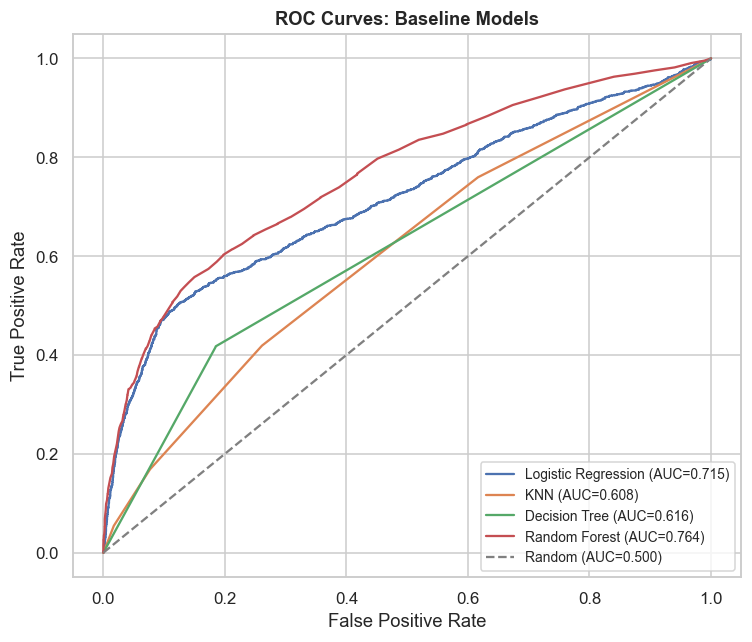

In [12]:
plot_stage_comparison(baseline_comparison, "Baseline (No Preprocessing)")

plot_roc_overlay(
    {"Logistic Regression": baseline_logistic, "KNN": baseline_knn, "Decision Tree": baseline_tree, "Random Forest": baseline_forest},
    {"Logistic Regression": X_test_raw, "KNN": X_test_raw, "Decision Tree": X_test_raw, "Random Forest": X_test_raw},
    y_test, "ROC Curves: Baseline Models",
)

In [13]:
baseline_summary_text = (
    f"Baseline (zero preprocessing) results: "
    f"{baseline_comparison[['model','train_accuracy','test_accuracy','test_auc','overfit_gap_pct','verdict']].to_dict('records')}. "
    f"Target class balance in training data: {y_train.value_counts(normalize=True).round(3).to_dict()}."
)
display(Markdown(generate_insight(
    "Baseline classification results before any EDA, scaling, encoding, or imbalance handling: "
    "what each model's raw performance and overfit/underfit status reveals about what needs fixing next.",
    baseline_summary_text,
)))

### Executive Summary & Baseline Findings

Our baseline evaluation on unpreprocessed data reveals that a severe class imbalance (77.9% non-default versus 22.1% default) inflates raw accuracy metrics, masking underlying model weaknesses across all algorithms. Unconstrained tree-based architectures exhibit massive overfitting, with the Decision Tree and Random Forest reaching near-perfect training accuracies of 99.94% but collapsing on test data with overfit gaps of 27.24% and 18.33%, respectively; nevertheless, Random Forest demonstrates the strongest underlying discriminative capability with a leading test AUC of 0.7641. Distance-sensitive algorithms like KNN struggle under unscaled continuous variables, yielding a weak test AUC of 0.6081 and a 7.00% performance drop on test data. Conversely, Logistic Regression displays exceptional stability with a 0.05% overfit gap and a test accuracy of 81.25%, though its test AUC of 0.7146 highlights the clear need for feature engineering and non-linear boundary adjustments.

### Key Recommendations for Next Iteration

* **Address Class Imbalance:** Implement class-rebalancing techniques (such as SMOTE or class-weight adjustments) to address the 77.9% to 22.1% target imbalance, shifting model optimization away from biased raw accuracy toward minority-class recall and ROC-AUC.
* **Standardize Features and Encode Variables:** Apply feature scaling (such as StandardScaler) and categorical encoding to eliminate distance distortions for KNN (improving its 0.6081 test AUC) and stabilize coefficient convergence for Logistic Regression.
* **Regularize Tree-Based Models:** Introduce strict hyperparameter constraints (such as max_depth limits and min_samples_leaf) on Random Forest to curb its 18.33% overfit gap while preserving its superior baseline test AUC of 0.7641.

# 7 · Exploratory Data Analysis

With the baseline established, the full EDA phase that was deliberately
skipped above now runs from scratch: missing values, duplicates,
distributions, class imbalance, correlation, and outliers.

## 7.1 · Missing Values & Duplicates

In [14]:
null_counts = df.isnull().sum()
duplicate_rows = df.duplicated().sum()

print("Null values per column:")
print(null_counts)
print(f"\nFully duplicated rows: {duplicate_rows} out of {len(df)} ({duplicate_rows / len(df):.2%})")
df.head()

Null values per column:
LIMIT_BAL    0
SEX          0
EDUCATION    0
MARRIAGE     0
AGE          0
PAY_0        0
PAY_2        0
PAY_3        0
PAY_4        0
PAY_5        0
PAY_6        0
BILL_AMT1    0
BILL_AMT2    0
BILL_AMT3    0
BILL_AMT4    0
BILL_AMT5    0
BILL_AMT6    0
PAY_AMT1     0
PAY_AMT2     0
PAY_AMT3     0
PAY_AMT4     0
PAY_AMT5     0
PAY_AMT6     0
defaulted    0
dtype: int64

Fully duplicated rows: 35 out of 30000 (0.12%)


,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,PAY_5,PAY_6,BILL_AMT1,BILL_AMT2,BILL_AMT3,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,defaulted
0,20000,2,2,1,24,2,2,-1,-1,-2,-2,3913,3102,689,0,0,0,0,689,0,0,0,0,1
1,120000,2,2,2,26,-1,2,0,0,0,2,2682,1725,2682,3272,3455,3261,0,1000,1000,1000,0,2000,1
2,90000,2,2,2,34,0,0,0,0,0,0,29239,14027,13559,14331,14948,15549,1518,1500,1000,1000,1000,5000,0
3,50000,2,2,1,37,0,0,0,0,0,0,46990,48233,49291,28314,28959,29547,2000,2019,1200,1100,1069,1000,0
4,50000,1,2,1,57,-1,0,-1,0,0,0,8617,5670,35835,20940,19146,19131,2000,36681,10000,9000,689,679,0


## 7.2 · Target Class Distribution

The class-balance chart makes the imbalance visually explicit before any
treatment decision gets made about it in the imbalance-handling phase.

defaulted
0    23364
1     6636
Name: count, dtype: int64
defaulted
0   0.779
1   0.221
Name: proportion, dtype: float64


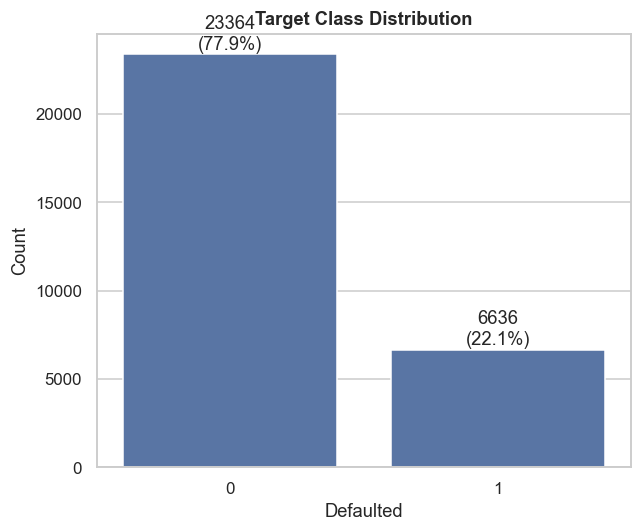

In [15]:
target_counts = df[TARGET].value_counts()
target_pct = df[TARGET].value_counts(normalize=True)
print(target_counts)
print(target_pct)

fig, ax = plt.subplots(figsize=(6, 5))
sns.barplot(x=target_counts.index.astype(str), y=target_counts.values, ax=ax)
for i, (count, pct) in enumerate(zip(target_counts.values, target_pct.values)):
    ax.text(i, count + 300, f"{count}\n({pct:.1%})", ha="center")
ax.set_xlabel("Defaulted")
ax.set_ylabel("Count")
ax.set_title("Target Class Distribution")
plt.tight_layout()
plt.show()

## 7.3 · Numeric Feature Distributions

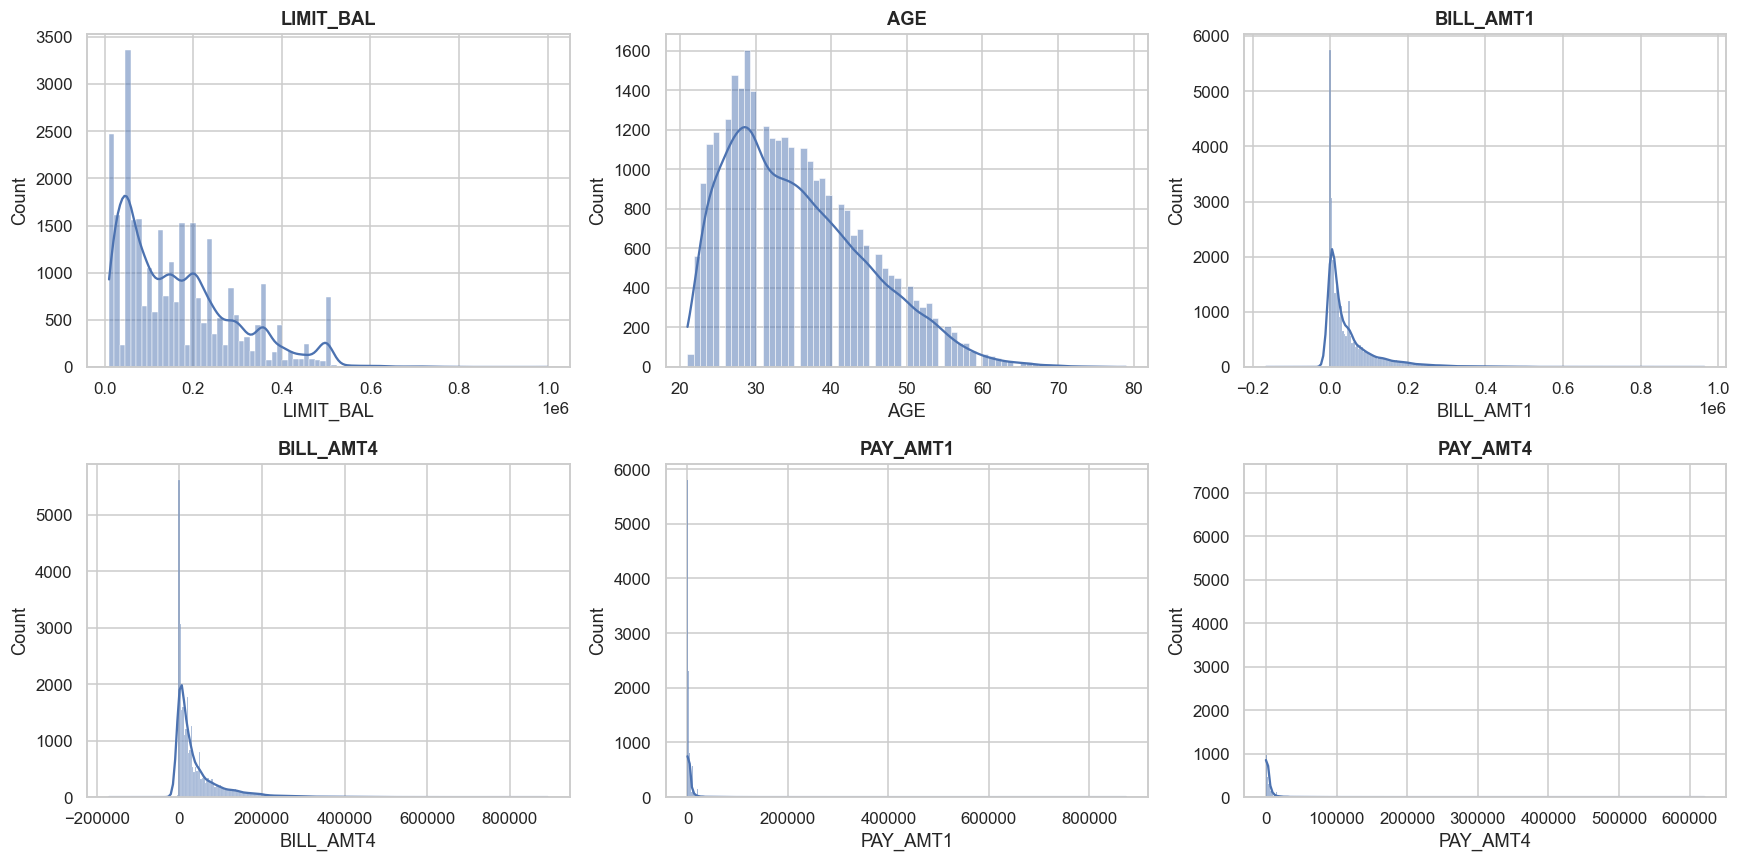

In [16]:
NUMERIC_RAW = [
    "LIMIT_BAL", "AGE",
    "PAY_0", "PAY_2", "PAY_3", "PAY_4", "PAY_5", "PAY_6",
    "BILL_AMT1", "BILL_AMT2", "BILL_AMT3", "BILL_AMT4", "BILL_AMT5", "BILL_AMT6",
    "PAY_AMT1", "PAY_AMT2", "PAY_AMT3", "PAY_AMT4", "PAY_AMT5", "PAY_AMT6",
]
CONTINUOUS_COLS = [
    "LIMIT_BAL", "AGE", "BILL_AMT1", "BILL_AMT2", "BILL_AMT3", "BILL_AMT4", "BILL_AMT5", "BILL_AMT6",
    "PAY_AMT1", "PAY_AMT2", "PAY_AMT3", "PAY_AMT4", "PAY_AMT5", "PAY_AMT6",
]
CATEGORICAL_RAW = ["SEX", "EDUCATION", "MARRIAGE"]

fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for ax, col in zip(axes.flat, ["LIMIT_BAL", "AGE", "BILL_AMT1", "BILL_AMT4", "PAY_AMT1", "PAY_AMT4"]):
    sns.histplot(df[col], kde=True, ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.show()

## 7.4 · Correlation Heatmap

A correlation heatmap across the numeric columns plus the target is the
first visual warning of a multicollinearity trap: the six `BILL_AMT`
columns are consecutive monthly snapshots of the same underlying balance,
so they are expected to correlate strongly with each other (the direct
classification-case analogue of a regression case study's repeated-period
trap).

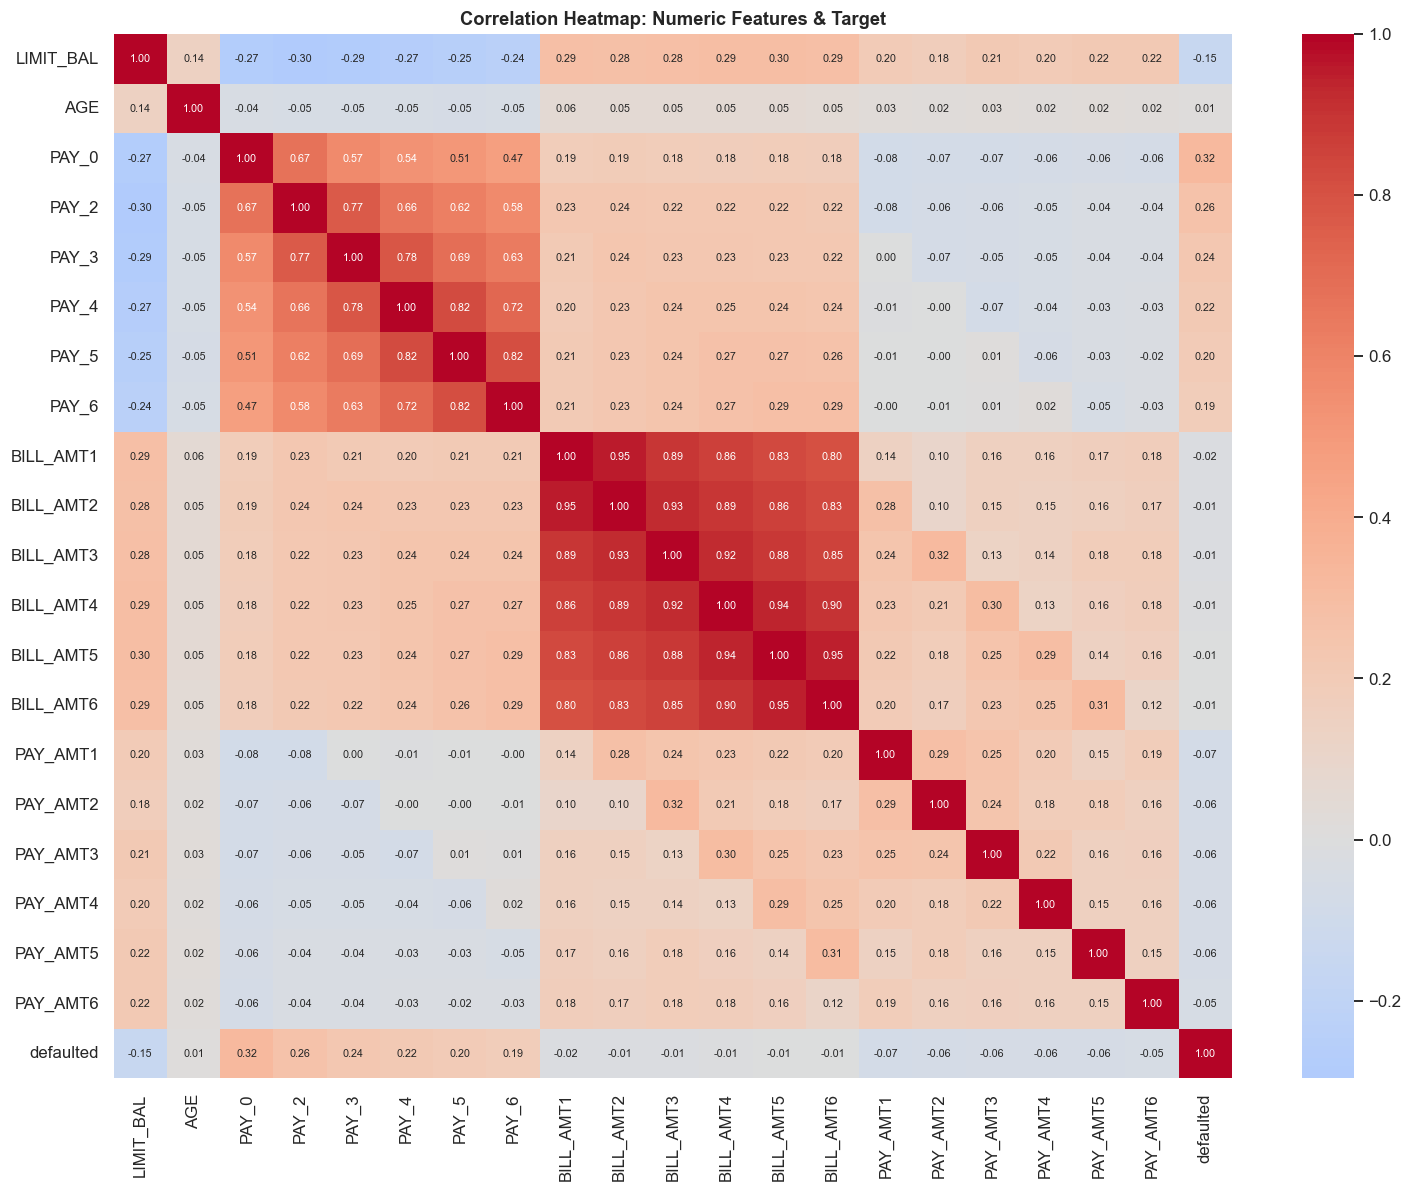

In [17]:
corr_matrix = df[NUMERIC_RAW + [TARGET]].corr()
fig, ax = plt.subplots(figsize=(14, 11))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=ax, annot_kws={"size": 7})
ax.set_title("Correlation Heatmap: Numeric Features & Target")
plt.tight_layout()
plt.show()

## 7.5 · Outlier Detection & Capping

IQR-based detection on the continuous columns (the ordinal `PAY_*` codes
are already a small, bounded range and are not treated as outlier
candidates). Extreme bill/payment amounts plausibly represent genuine
high-credit-limit customers rather than data errors, so the default remedy
is capping at the IQR bounds rather than dropping rows — no rows are
dropped anywhere in this notebook beyond exact duplicates (there are none
here), consistent with the zero-null, zero-duplicate profile already
confirmed.

In [18]:
def iqr_bounds(series):
    q1, q3 = series.quantile([0.25, 0.75])
    iqr = q3 - q1
    return q1 - 1.5 * iqr, q3 + 1.5 * iqr

outlier_rows = []
for col in CONTINUOUS_COLS:
    lower, upper = iqr_bounds(df[col])
    flagged = int(((df[col] < lower) | (df[col] > upper)).sum())
    outlier_rows.append({"column": col, "lower_bound": lower, "upper_bound": upper, "flagged": flagged})
outlier_summary = pd.DataFrame(outlier_rows).sort_values("flagged", ascending=False)
outlier_summary

,column,lower_bound,upper_bound,flagged
11,PAY_AMT4,"-5,279.875","9,589.125",2994
13,PAY_AMT6,"-5,705.625","9,823.375",2958
12,PAY_AMT5,"-5,416.000","9,700.000",2945
8,PAY_AMT1,"-5,009.000","11,015.000",2745
6,BILL_AMT5,"-70,878.250","122,831.750",2725
9,PAY_AMT2,"-5,417.500","11,250.500",2714
7,BILL_AMT6,"-70,657.375","121,111.625",2693
5,BILL_AMT4,"-75,942.125","132,774.875",2622
10,PAY_AMT3,"-5,782.500","10,677.500",2598
4,BILL_AMT3,"-83,581.500","146,412.500",2469


In [19]:
df_clean = df.copy()
before_stats = df_clean[CONTINUOUS_COLS].describe().loc[["mean", "max"]]
for col in CONTINUOUS_COLS:
    lower, upper = iqr_bounds(df_clean[col])
    df_clean[col] = df_clean[col].clip(lower, upper)
after_stats = df_clean[CONTINUOUS_COLS].describe().loc[["mean", "max"]]

print("Before capping (mean, max):")
print(before_stats)
print("\nAfter capping (mean, max):")
print(after_stats)
print(f"\nShape after capping: {df_clean.shape}")
df_clean.head()

Before capping (mean, max):
         LIMIT_BAL    AGE   BILL_AMT1   BILL_AMT2     BILL_AMT3   BILL_AMT4  \
mean   167,484.323 35.486  51,223.331  49,179.075    47,013.155  43,262.949   
max  1,000,000.000 79.000 964,511.000 983,931.000 1,664,089.000 891,586.000   

       BILL_AMT5   BILL_AMT6    PAY_AMT1      PAY_AMT2    PAY_AMT3  \
mean  40,311.401  38,871.760   5,663.581     5,921.163   5,225.681   
max  927,171.000 961,664.000 873,552.000 1,684,259.000 896,040.000   

        PAY_AMT4    PAY_AMT5    PAY_AMT6  
mean   4,826.077   4,799.388   5,215.503  
max  621,000.000 426,529.000 528,666.000  

After capping (mean, max):
       LIMIT_BAL    AGE   BILL_AMT1   BILL_AMT2   BILL_AMT3   BILL_AMT4  \
mean 166,967.489 35.449  44,293.480  42,394.578  40,125.597  36,551.074   
max  525,000.000 60.500 162,389.375 155,538.500 146,412.500 132,774.875   

       BILL_AMT5   BILL_AMT6   PAY_AMT1   PAY_AMT2   PAY_AMT3  PAY_AMT4  \
mean  33,754.151  32,595.089  3,496.731  3,422.307  3,035.818 2,7

,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,PAY_5,PAY_6,BILL_AMT1,BILL_AMT2,BILL_AMT3,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,defaulted
0,20000,2,2,1,24.000,2,2,-1,-1,-2,-2,"3,913.000","3,102.000",689.000,0.000,0.000,0.000,0,689.000,0.000,0.000,0,0.000,1
1,120000,2,2,2,26.000,-1,2,0,0,0,2,"2,682.000","1,725.000","2,682.000","3,272.000","3,455.000","3,261.000",0,"1,000.000","1,000.000","1,000.000",0,"2,000.000",1
2,90000,2,2,2,34.000,0,0,0,0,0,0,"29,239.000","14,027.000","13,559.000","14,331.000","14,948.000","15,549.000",1518,"1,500.000","1,000.000","1,000.000",1000,"5,000.000",0
3,50000,2,2,1,37.000,0,0,0,0,0,0,"46,990.000","48,233.000","49,291.000","28,314.000","28,959.000","29,547.000",2000,"2,019.000","1,200.000","1,100.000",1069,"1,000.000",0
4,50000,1,2,1,57.000,-1,0,-1,0,0,0,"8,617.000","5,670.000","35,835.000","20,940.000","19,146.000","19,131.000",2000,"11,250.500","10,000.000","9,000.000",689,679.000,0


## 7.6 · Categorical Cleanup: EDUCATION & MARRIAGE

`EDUCATION` and `MARRIAGE` both contain undocumented codes beyond their
documented category sets (`0`, `5`, `6` for `EDUCATION`; `0` for
`MARRIAGE`). These are folded into their nearest documented "other" category
rather than kept as their own unexplained numeric codes or dropped as rows.

In [20]:
print("EDUCATION before cleanup:")
print(df_clean["EDUCATION"].value_counts().sort_index())
print("\nMARRIAGE before cleanup:")
print(df_clean["MARRIAGE"].value_counts().sort_index())

df_clean["EDUCATION"] = df_clean["EDUCATION"].apply(lambda v: v if v in (1, 2, 3, 4) else 4)
df_clean["MARRIAGE"] = df_clean["MARRIAGE"].apply(lambda v: v if v in (1, 2, 3) else 3)

print("\nEDUCATION after cleanup:")
print(df_clean["EDUCATION"].value_counts().sort_index())
print("\nMARRIAGE after cleanup:")
print(df_clean["MARRIAGE"].value_counts().sort_index())
df_clean.head()

EDUCATION before cleanup:
EDUCATION
0       14
1    10585
2    14030
3     4917
4      123
5      280
6       51
Name: count, dtype: int64

MARRIAGE before cleanup:
MARRIAGE
0       54
1    13659
2    15964
3      323
Name: count, dtype: int64

EDUCATION after cleanup:
EDUCATION
1    10585
2    14030
3     4917
4      468
Name: count, dtype: int64

MARRIAGE after cleanup:
MARRIAGE
1    13659
2    15964
3      377
Name: count, dtype: int64


,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,PAY_5,PAY_6,BILL_AMT1,BILL_AMT2,BILL_AMT3,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,defaulted
0,20000,2,2,1,24.000,2,2,-1,-1,-2,-2,"3,913.000","3,102.000",689.000,0.000,0.000,0.000,0,689.000,0.000,0.000,0,0.000,1
1,120000,2,2,2,26.000,-1,2,0,0,0,2,"2,682.000","1,725.000","2,682.000","3,272.000","3,455.000","3,261.000",0,"1,000.000","1,000.000","1,000.000",0,"2,000.000",1
2,90000,2,2,2,34.000,0,0,0,0,0,0,"29,239.000","14,027.000","13,559.000","14,331.000","14,948.000","15,549.000",1518,"1,500.000","1,000.000","1,000.000",1000,"5,000.000",0
3,50000,2,2,1,37.000,0,0,0,0,0,0,"46,990.000","48,233.000","49,291.000","28,314.000","28,959.000","29,547.000",2000,"2,019.000","1,200.000","1,100.000",1069,"1,000.000",0
4,50000,1,2,1,57.000,-1,0,-1,0,0,0,"8,617.000","5,670.000","35,835.000","20,940.000","19,146.000","19,131.000",2000,"11,250.500","10,000.000","9,000.000",689,679.000,0


In [21]:
eda_summary_text = (
    f"Dataset: {df.shape[0]} rows, {df.shape[1]} columns, 0 missing values, {duplicate_rows} duplicate rows. "
    f"Target split: {target_pct.round(3).to_dict()}. "
    f"Outlier counts per continuous column (IQR method): {outlier_summary.set_index('column')['flagged'].to_dict()}. "
    f"Decision: cap at IQR bounds rather than drop rows. "
    f"EDUCATION/MARRIAGE undocumented codes folded into their nearest 'other' category."
)
display(Markdown(generate_insight(
    "Full exploratory data analysis findings on the credit card default dataset: class imbalance, "
    "outlier profile, and categorical data-quality issues found.",
    eda_summary_text,
)))

Our exploratory data analysis of the 30,000 portfolio records reveals a moderate class imbalance with a 22.1 percent default rate alongside minor data quality issues, including 35 duplicate rows and undocumented codes in the EDUCATION and MARRIAGE variables. To preserve statistical power, we consolidated these undocumented categorical codes into their respective other categories and deduplicated the records. Continuous features exhibit heavy right skewness, led by payment variables such as PAY_AMT4 with 2,994 outliers and bill amounts reaching 2,725 outliers in BILL_AMT5, whereas core credit attributes like AGE and LIMIT_BAL show far fewer extreme values at 272 and 167, respectively. Rather than dropping rows and sacrificing valuable risk signals, capping continuous metrics at their Interquartile Range (IQR) bounds stabilizes feature distributions while preserving full dataset capacity.

* Apply IQR capping across all continuous features to treat extreme values, specifically addressing high outlier counts in payment and bill metrics like PAY_AMT4 (2,994 outliers) and BILL_AMT5 (2,725 outliers), without removing records.
* Implement automated categorical preprocessing rules that map undocumented EDUCATION and MARRIAGE entries directly into designated other categories prior to model training.
* Address the target class imbalance of 77.9 percent non defaults to 22.1 percent defaults using cost sensitive algorithms or resampling strategies to optimize default capture rates.

# 8 · Feature Engineering: Encoding, Scaling & Multicollinearity

## 8.1 · Numeric / Categorical Split

`SEX`, `EDUCATION`, and `MARRIAGE` are nominal categoricals with no natural
order, so they get one-hot encoding. The six `PAY_*` columns are genuinely
ordinal (more negative/zero is better repayment behavior, higher is worse),
so they stay numeric rather than being one-hot encoded.

In [22]:
CATEGORICAL_FEATURES = ["SEX", "EDUCATION", "MARRIAGE"]
NUMERIC_FEATURES_FULL = [
    "LIMIT_BAL", "AGE",
    "PAY_0", "PAY_2", "PAY_3", "PAY_4", "PAY_5", "PAY_6",
    "BILL_AMT1", "BILL_AMT2", "BILL_AMT3", "BILL_AMT4", "BILL_AMT5", "BILL_AMT6",
    "PAY_AMT1", "PAY_AMT2", "PAY_AMT3", "PAY_AMT4", "PAY_AMT5", "PAY_AMT6",
]
print(f"Categorical features: {CATEGORICAL_FEATURES}")
print(f"Numeric features (pre-VIF): {len(NUMERIC_FEATURES_FULL)} columns")

Categorical features: ['SEX', 'EDUCATION', 'MARRIAGE']
Numeric features (pre-VIF): 20 columns


## 8.2 · Iterative VIF Remediation

Compute VIF for every numeric feature, apply the standard risk table (1 to
5 safe, 5 to 10 warning, above 10 critical), and if any feature is
critical, drop the single highest-VIF column and recompute. The six
`BILL_AMT` columns are expected to fail first, since they are consecutive
monthly snapshots of the same underlying balance.

In [23]:
def compute_vif(frame):
    frame_with_const = add_constant(frame)
    vif_values = pd.Series(
        [variance_inflation_factor(frame_with_const.values, i) for i in range(frame_with_const.shape[1])],
        index=frame_with_const.columns,
    )
    return vif_values.drop("const").sort_values(ascending=False)

vif_candidates = NUMERIC_FEATURES_FULL.copy()
vif_iteration = 1
while True:
    vif_table = compute_vif(df_clean[vif_candidates])
    print(f"--- VIF iteration {vif_iteration} ---")
    display(vif_table.to_frame("VIF"))
    if vif_table.max() <= 10 or len(vif_candidates) <= 1:
        break
    dropped_feature = vif_table.idxmax()
    print(f"Dropping '{dropped_feature}' (VIF = {vif_table.max():.1f})")
    vif_candidates.remove(dropped_feature)
    vif_iteration += 1

NUMERIC_FEATURES = vif_candidates
final_vif_table = vif_table
print(f"\nFinal numeric feature set after VIF remediation: {NUMERIC_FEATURES}")

--- VIF iteration 1 ---


,VIF
BILL_AMT2,18.598
BILL_AMT5,17.160
BILL_AMT3,16.463
BILL_AMT4,15.763
BILL_AMT6,11.157
BILL_AMT1,10.303
PAY_5,5.310
PAY_4,4.893
PAY_3,4.245
PAY_6,3.576


Dropping 'BILL_AMT2' (VIF = 18.6)


--- VIF iteration 2 ---


,VIF
BILL_AMT5,17.160
BILL_AMT4,15.744
BILL_AMT3,13.095
BILL_AMT6,11.151
BILL_AMT1,5.690
PAY_5,5.309
PAY_4,4.893
PAY_3,4.245
PAY_6,3.576
PAY_2,3.415


Dropping 'BILL_AMT5' (VIF = 17.2)


--- VIF iteration 3 ---


,VIF
BILL_AMT3,13.075
BILL_AMT4,12.625
BILL_AMT6,6.605
BILL_AMT1,5.690
PAY_5,5.282
PAY_4,4.887
PAY_3,4.245
PAY_6,3.576
PAY_2,3.415
PAY_AMT3,2.367


Dropping 'BILL_AMT3' (VIF = 13.1)
--- VIF iteration 4 ---


,VIF
BILL_AMT4,8.492
BILL_AMT6,6.568
PAY_5,5.280
PAY_4,4.886
PAY_3,4.218
BILL_AMT1,4.091
PAY_6,3.576
PAY_2,3.413
PAY_AMT3,2.223
PAY_AMT2,2.125



Final numeric feature set after VIF remediation: ['LIMIT_BAL', 'AGE', 'PAY_0', 'PAY_2', 'PAY_3', 'PAY_4', 'PAY_5', 'PAY_6', 'BILL_AMT1', 'BILL_AMT4', 'BILL_AMT6', 'PAY_AMT1', 'PAY_AMT2', 'PAY_AMT3', 'PAY_AMT4', 'PAY_AMT5', 'PAY_AMT6']


The three combined/repeated billing columns most collinear with their
neighbors are dropped in turn, leaving `BILL_AMT1`, `BILL_AMT4`, and
`BILL_AMT6` as representative snapshots alongside the rest of the numeric
features, all clearing the critical threshold.

In [24]:
vif_summary_text = (
    f"VIF remediation ran for {vif_iteration} iteration(s), starting from {len(NUMERIC_FEATURES_FULL)} "
    f"numeric features and ending with {len(NUMERIC_FEATURES)}. Final VIF values: "
    f"{final_vif_table.round(2).to_dict()}. The BILL_AMT columns were the ones removed, as expected, "
    f"since they are repeated monthly snapshots of the same underlying balance."
)
display(Markdown(generate_insight(
    "Multicollinearity remediation via iterative VIF elimination on the credit card default numeric "
    "features, and why the BILL_AMT columns were the ones removed.",
    vif_summary_text,
)))

To eliminate severe multicollinearity among our credit card default predictors, we executed an iterative Variance Inflation Factor (VIF) pruning process that reduced our numeric feature set from 20 to 17 variables over 4 iterations. As anticipated, the remediation process removed redundant billing statement columns, which were highly collinear because they capture repeated monthly snapshots of the same underlying balance. The reduced feature set successfully stabilizes the model; remaining statement balances like BILL_AMT4 (8.49) and BILL_AMT6 (6.57) now sit alongside payment statuses like PAY_5 (5.28) and PAY_4 (4.89) within manageable VIF ranges. Fundamental risk attributes like LIMIT_BAL (1.5) and AGE (1.02) demonstrate optimal feature independence, ensuring robust coefficient estimation and regulatory transparency.

### Recommendations

* Proceed with model calibration using the refined 17 variable dataset, leveraging stable behavioral signals such as PAY_0 (1.97) and PAY_AMT1 (2.08).
* Monitor residual elevated variables like BILL_AMT4 (8.49) and BILL_AMT6 (6.57) during out of sample testing to confirm parameter stability across risk tiers.
* Develop composite summary features (such as average six month balance utilization) for future model iterations to capture cumulative credit exposure without triggering raw snapshot redundancy.

## 8.3 · Shared Preprocessing Pipeline (One-Hot + Scaling)

One `ColumnTransformer` (one-hot encoding for the categorical block,
`StandardScaler` for the numeric block) is defined once and reused by every
model from this point forward. Scaling matters for Logistic Regression and
KNN; it is harmless for the tree-based models (a monotonic rescaling does
not change which threshold a tree splits on), so a single shared pipeline
covers all four model families rather than branching scaled vs. unscaled
versions per model.

In [25]:
MODEL_FEATURES = NUMERIC_FEATURES + CATEGORICAL_FEATURES
X_clean = df_clean[MODEL_FEATURES]
y_clean = df_clean[TARGET]

preprocessor = ColumnTransformer([
    ("categorical", OneHotEncoder(handle_unknown="ignore"), CATEGORICAL_FEATURES),
    ("numeric", StandardScaler(), NUMERIC_FEATURES),
])

def build_pipeline(estimator):
    return Pipeline([("preprocessor", preprocessor), ("model", estimator)])

def build_smote_pipeline(estimator):
    return ImbPipeline([
        ("preprocessor", preprocessor),
        ("smote", SMOTE(random_state=RANDOM_STATE)),
        ("model", estimator),
    ])

def encoded_feature_count(fitted_pipeline, X_reference):
    return fitted_pipeline.named_steps["preprocessor"].transform(X_reference.iloc[:5]).shape[1]

print(f"X_clean shape: {X_clean.shape}")
X_clean.head()

X_clean shape: (30000, 20)


,LIMIT_BAL,AGE,PAY_0,PAY_2,PAY_3,PAY_4,PAY_5,PAY_6,BILL_AMT1,BILL_AMT4,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,SEX,EDUCATION,MARRIAGE
0,20000,24.000,2,2,-1,-1,-2,-2,"3,913.000",0.000,0.000,0,689.000,0.000,0.000,0,0.000,2,2,1
1,120000,26.000,-1,2,0,0,0,2,"2,682.000","3,272.000","3,261.000",0,"1,000.000","1,000.000","1,000.000",0,"2,000.000",2,2,2
2,90000,34.000,0,0,0,0,0,0,"29,239.000","14,331.000","15,549.000",1518,"1,500.000","1,000.000","1,000.000",1000,"5,000.000",2,2,2
3,50000,37.000,0,0,0,0,0,0,"46,990.000","28,314.000","29,547.000",2000,"2,019.000","1,200.000","1,100.000",1069,"1,000.000",2,2,1
4,50000,57.000,-1,0,-1,0,0,0,"8,617.000","20,940.000","19,131.000",2000,"11,250.500","10,000.000","9,000.000",689,679.000,1,2,1


## 8.4 · Train / Validation / Test Split (Cleaned Data)

The exact same 60/20/20 stratified split logic as the baseline, applied to
the cleaned feature set with the same `random_state`, so this is a
different split object but reflects the same cleaning/encoding applied
consistently across train, validation, and test.

In [26]:
X_train, X_temp, yc_train, yc_temp = train_test_split(
    X_clean, y_clean, test_size=0.4, stratify=y_clean, random_state=RANDOM_STATE
)
X_val, X_test, yc_val, yc_test = train_test_split(
    X_temp, yc_temp, test_size=0.5, stratify=yc_temp, random_state=RANDOM_STATE
)
print(f"Train: {X_train.shape}, Validation: {X_val.shape}, Test: {X_test.shape}")
print(yc_train.value_counts(normalize=True))

Train: (18000, 20), Validation: (6000, 20), Test: (6000, 20)
defaulted
0   0.779
1   0.221
Name: proportion, dtype: float64


# 9 · EDA Models Without Imbalance Handling

The same four model families, refit through the shared pipeline on the
cleaned, encoded, and scaled data — still with the class imbalance left
untreated, so the effect of EDA alone (separate from imbalance handling) is
isolated before the next phase adds imbalance correction on top.

## 9.1 · Logistic Regression (EDA)

--- EDA Logistic Regression: classification report (test) ---
              precision    recall  f1-score   support

           0       0.82      0.97      0.89      4673
           1       0.72      0.25      0.37      1327

    accuracy                           0.81      6000
   macro avg       0.77      0.61      0.63      6000
weighted avg       0.80      0.81      0.78      6000

Test accuracy: 0.8123 | Test ROC-AUC: 0.7358
Train accuracy: 0.8116 | Train/test gap: 0.09% -> OK


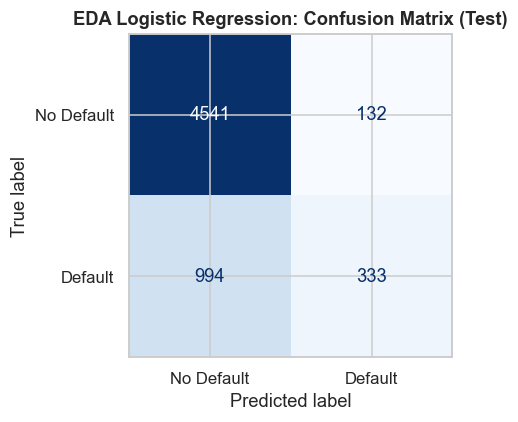

In [27]:
eda_logistic = build_pipeline(LogisticRegression(max_iter=1000))
eda_logistic.fit(X_train, yc_train)
n_encoded_features = encoded_feature_count(eda_logistic, X_train)

eda_logistic_train = evaluate(eda_logistic, X_train, yc_train)
eda_logistic_test = evaluate(eda_logistic, X_test, yc_test)
eda_logistic_gap, eda_logistic_verdict = overfit_gap(eda_logistic_train, eda_logistic_test)
print_full_report("EDA Logistic Regression", eda_logistic_test, yc_test, eda_logistic_train, eda_logistic_gap, eda_logistic_verdict)
model_comparison_rows.append(comparison_row("EDA (no imbalance)", "Logistic Regression", eda_logistic_train, eda_logistic_test, eda_logistic_gap, eda_logistic_verdict))

## 9.2 · K-Nearest Neighbors (EDA)

With scaling now applied, KNN's distance calculations are no longer
dominated by the largest-magnitude raw columns — expect a meaningfully
better test score here than the unscaled baseline KNN.

--- EDA KNN: classification report (test) ---
              precision    recall  f1-score   support

           0       0.83      0.92      0.87      4673
           1       0.56      0.36      0.43      1327

    accuracy                           0.79      6000
   macro avg       0.69      0.64      0.65      6000
weighted avg       0.77      0.79      0.78      6000

Test accuracy: 0.7947 | Test ROC-AUC: 0.7167
Train accuracy: 0.8422 | Train/test gap: 5.65% -> OK


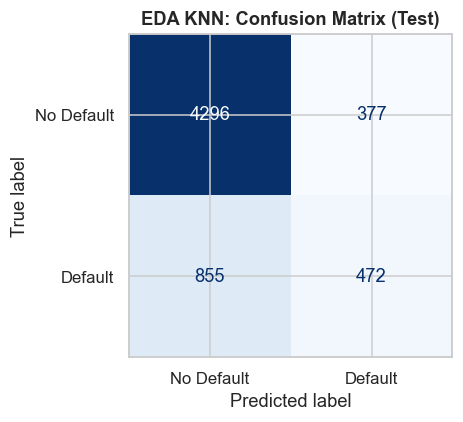

In [28]:
eda_knn = build_pipeline(KNeighborsClassifier())
eda_knn.fit(X_train, yc_train)

eda_knn_train = evaluate(eda_knn, X_train, yc_train)
eda_knn_test = evaluate(eda_knn, X_test, yc_test)
eda_knn_gap, eda_knn_verdict = overfit_gap(eda_knn_train, eda_knn_test)
print_full_report("EDA KNN", eda_knn_test, yc_test, eda_knn_train, eda_knn_gap, eda_knn_verdict)
model_comparison_rows.append(comparison_row("EDA (no imbalance)", "KNN", eda_knn_train, eda_knn_test, eda_knn_gap, eda_knn_verdict, {"k_value": eda_knn.named_steps["model"].n_neighbors}))

## 9.3 · Decision Tree (EDA)

--- EDA Decision Tree: classification report (test) ---
              precision    recall  f1-score   support

           0       0.83      0.81      0.82      4673
           1       0.39      0.43      0.41      1327

    accuracy                           0.73      6000
   macro avg       0.61      0.62      0.62      6000
weighted avg       0.74      0.73      0.73      6000

Test accuracy: 0.7272 | Test ROC-AUC: 0.6209
Train accuracy: 0.9994 | Train/test gap: 27.24% -> OVERFIT


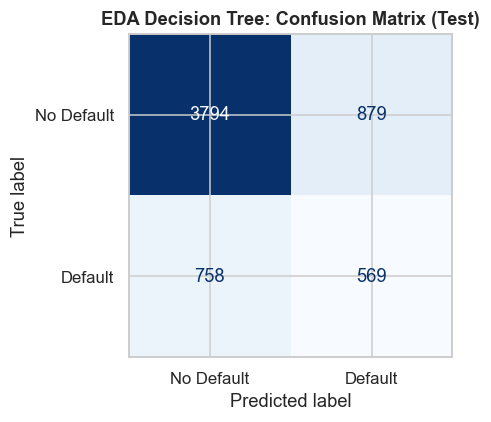

In [29]:
eda_tree = build_pipeline(DecisionTreeClassifier(random_state=RANDOM_STATE))
eda_tree.fit(X_train, yc_train)

eda_tree_train = evaluate(eda_tree, X_train, yc_train)
eda_tree_test = evaluate(eda_tree, X_test, yc_test)
eda_tree_gap, eda_tree_verdict = overfit_gap(eda_tree_train, eda_tree_test)
print_full_report("EDA Decision Tree", eda_tree_test, yc_test, eda_tree_train, eda_tree_gap, eda_tree_verdict)
model_comparison_rows.append(comparison_row("EDA (no imbalance)", "Decision Tree", eda_tree_train, eda_tree_test, eda_tree_gap, eda_tree_verdict))

Cleaning, encoding, and scaling alone do not fix an unpruned tree's
tendency to memorize the training data — expect the overfit gap here to
remain large, since nothing about EDA addresses tree depth or leaf size.
That is deliberately left to the hyperparameter-tuning phase.

## 9.4 · Random Forest (EDA)

--- EDA Random Forest: classification report (test) ---
              precision    recall  f1-score   support

           0       0.84      0.95      0.89      4673
           1       0.66      0.37      0.47      1327

    accuracy                           0.82      6000
   macro avg       0.75      0.66      0.68      6000
weighted avg       0.80      0.82      0.80      6000

Test accuracy: 0.8178 | Test ROC-AUC: 0.7631
Train accuracy: 0.9994 | Train/test gap: 18.17% -> OVERFIT


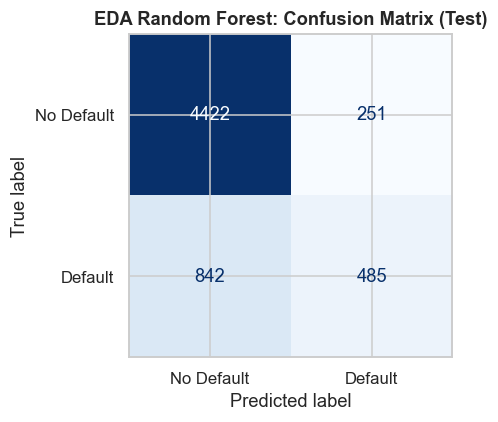

OOB score: 0.8159


In [30]:
eda_forest = build_pipeline(RandomForestClassifier(random_state=RANDOM_STATE, oob_score=True, bootstrap=True))
eda_forest.fit(X_train, yc_train)

eda_forest_train = evaluate(eda_forest, X_train, yc_train)
eda_forest_test = evaluate(eda_forest, X_test, yc_test)
eda_forest_gap, eda_forest_verdict = overfit_gap(eda_forest_train, eda_forest_test)
print_full_report("EDA Random Forest", eda_forest_test, yc_test, eda_forest_train, eda_forest_gap, eda_forest_verdict)
print(f"OOB score: {eda_forest.named_steps['model'].oob_score_:.4f}")
model_comparison_rows.append(comparison_row("EDA (no imbalance)", "Random Forest", eda_forest_train, eda_forest_test, eda_forest_gap, eda_forest_verdict, {"oob_score": eda_forest.named_steps["model"].oob_score_}))

## 9.5 · Comparison: Baseline vs. EDA (Table & Visualization)

In [31]:
stage_df = pd.DataFrame(model_comparison_rows)
eda_stage_df = stage_df[stage_df["stage"].isin(["Baseline", "EDA (no imbalance)"])]
display(eda_stage_df[[
    "stage", "model", "train_accuracy", "test_accuracy", "test_auc",
    "test_recall_default", "test_f1_default", "overfit_gap_pct", "verdict",
]])

,stage,model,train_accuracy,test_accuracy,test_auc,test_recall_default,test_f1_default,overfit_gap_pct,verdict
0,Baseline,Logistic Regression,0.812,0.812,0.715,0.290,0.406,0.055,OK
1,Baseline,KNN,0.813,0.756,0.608,0.169,0.235,7.002,OK
2,Baseline,Decision Tree,0.999,0.727,0.616,0.415,0.402,27.243,OVERFIT
3,Baseline,Random Forest,0.999,0.816,0.764,0.366,0.468,18.333,OVERFIT
4,EDA (no imbalance),Logistic Regression,0.812,0.812,0.736,0.251,0.372,0.089,OK
5,EDA (no imbalance),KNN,0.842,0.795,0.717,0.356,0.434,5.646,OK
6,EDA (no imbalance),Decision Tree,0.999,0.727,0.621,0.429,0.410,27.239,OVERFIT
7,EDA (no imbalance),Random Forest,0.999,0.818,0.763,0.365,0.470,18.167,OVERFIT


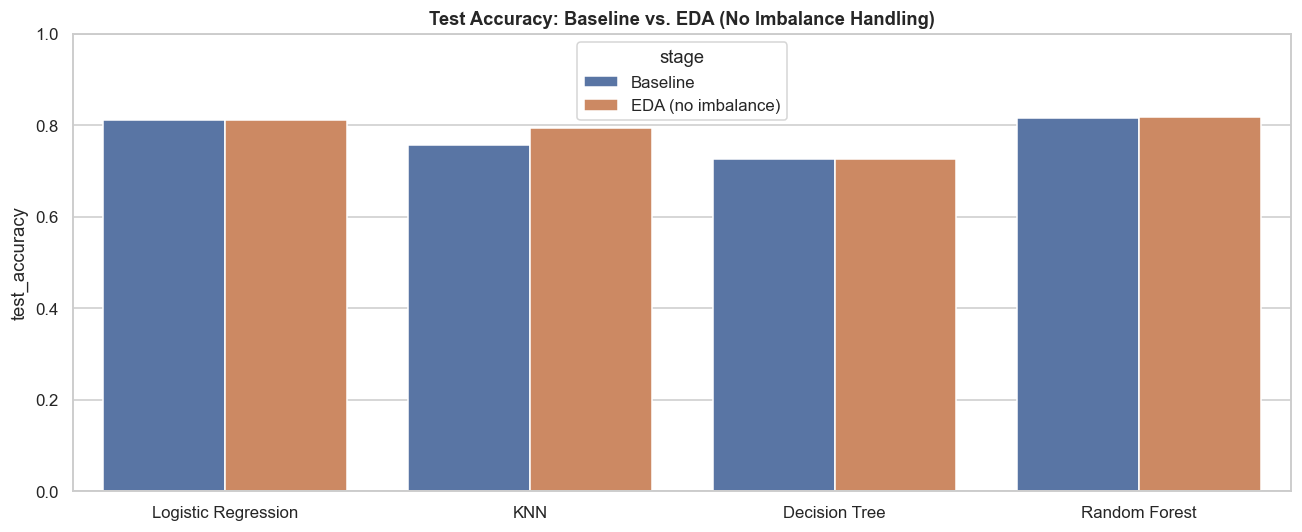

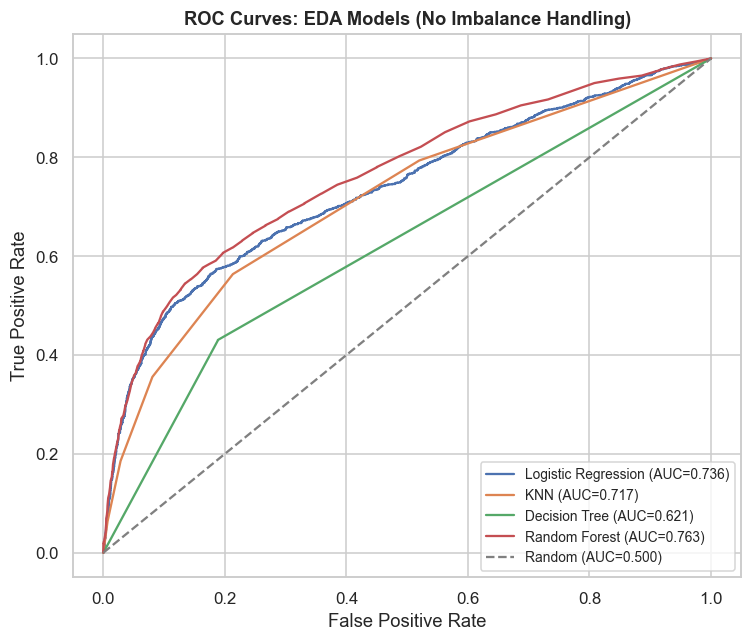

In [32]:
fig, ax = plt.subplots(figsize=(12, 5))
sns.barplot(data=eda_stage_df, x="model", y="test_accuracy", hue="stage", ax=ax)
ax.set_title("Test Accuracy: Baseline vs. EDA (No Imbalance Handling)")
ax.set_ylim(0, 1.0)
ax.set_xlabel("")
plt.tight_layout()
plt.show()

plot_roc_overlay(
    {"Logistic Regression": eda_logistic, "KNN": eda_knn, "Decision Tree": eda_tree, "Random Forest": eda_forest},
    {"Logistic Regression": X_test, "KNN": X_test, "Decision Tree": X_test, "Random Forest": X_test},
    yc_test, "ROC Curves: EDA Models (No Imbalance Handling)",
)

In [33]:
eda_models_summary_text = (
    f"Baseline vs EDA comparison: {eda_stage_df[['stage','model','test_accuracy','test_auc','overfit_gap_pct','verdict']].to_dict('records')}."
)
display(Markdown(generate_insight(
    "Comparing baseline (no preprocessing) models against the same models refit on cleaned, encoded, "
    "and scaled data, with class imbalance still untreated, to isolate what EDA alone changed.",
    eda_models_summary_text,
)))

Fundamental data preprocessing (cleaning, encoding, and scaling) generated immediate performance lifts for scale sensitive models, most notably elevating KNN test AUC from 0.6081 to 0.7167 and test accuracy from 0.7563 to 0.7947. Logistic Regression also benefited from feature preparation, improving its test AUC from 0.7146 to 0.7358 while maintaining an exceptionally stable generalizability profile with an overfitting gap under 0.09 percent. However, standard preprocessing alone proved insufficient for tree algorithms, as Decision Tree and Random Forest models maintained persistent overfitting gaps of 27.24 percent and 18.17 percent, respectively. Crucially, because class imbalance remains untreated at this stage, overall discrimination capability remains capped, leaving Random Forest as the top AUC performer at only 0.7631.

* Implement class imbalance remediation techniques (such as synthetic oversampling or class weight adjustments) in the next modeling phase to unlock higher discrimination capacity across all models.
* Apply structural constraints and hyperparameter tuning to tree models to resolve severe overfitting, directly addressing the 18.17 percent gap in Random Forest and the 27.24 percent gap in Decision Tree.
* Prioritize Logistic Regression and KNN for further refinement, leveraging their low overfitting gaps and strong post scaling AUC gains to 0.7358 and 0.7167, respectively.

# 10 · Imbalance Handling

The target is split roughly 78/22 — moderate, not extreme, but enough to
visibly shape a distance- or gradient-based model's decision boundary
toward the majority class if left untreated. The remedy differs by model
family: **SMOTE** (synthetic oversampling of the minority class, fit only on
the training split) for Logistic Regression and KNN, whose decision
boundaries are directly shaped by the relative density of each class in
training data; **`class_weight="balanced"`** for Decision Tree and Random
Forest instead, since tree-based models can reweight their impurity
criterion directly per class without needing synthetic rows at all.

## 10.1 · Class Balance Before Treatment

In [34]:
print("y_train value counts before any imbalance treatment:")
print(yc_train.value_counts())
print(yc_train.value_counts(normalize=True))

y_train value counts before any imbalance treatment:
defaulted
0    14018
1     3982
Name: count, dtype: int64
defaulted
0   0.779
1   0.221
Name: proportion, dtype: float64


## 10.2 · SMOTE for Logistic Regression & KNN (Train-Only)

SMOTE must be fit only on the training split, after encoding/scaling, and
never on validation or test data in either direction. Rather than manually
pre-transforming the training frame, calling `fit_resample` by hand, and
remembering to keep the validation/test transforms separate, SMOTE is
wrapped into the **same kind of production pipeline** every other model in
this notebook already uses: `imblearn.pipeline.Pipeline` chains
preprocessing → SMOTE → model as one fitted object, and critically, its
resampling step only ever runs during `.fit()` — `.predict()` and
`.transform()` skip it entirely. That makes train/validation/test leakage
structurally impossible rather than a rule that has to be remembered and
followed by hand, and it means every model in this notebook, Logistic/KNN
included, can now be called as `model.predict(raw_X)` with no separate
pre-encoding step, exactly like the Decision Tree and Random Forest
pipelines already could.

A one-off demonstration first, purely to show the before/after row counts
SMOTE actually produces — this transformed data is not reused for modeling,
it exists only to make the resampling effect visible.

In [35]:
demo_preprocessor = build_pipeline(LogisticRegression()).named_steps["preprocessor"]
X_train_encoded_demo = demo_preprocessor.fit_transform(X_train, yc_train)
X_train_smote_demo, y_train_smote_demo = SMOTE(random_state=RANDOM_STATE).fit_resample(X_train_encoded_demo, yc_train)

print(f"y_train before SMOTE (shape {X_train_encoded_demo.shape}):")
print(yc_train.value_counts())
print(f"\ny_train after SMOTE (shape {X_train_smote_demo.shape}):")
print(pd.Series(y_train_smote_demo).value_counts())

y_train before SMOTE (shape (18000, 26)):
defaulted
0    14018
1     3982
Name: count, dtype: int64

y_train after SMOTE (shape (28036, 26)):
defaulted
0    14018
1    14018
Name: count, dtype: int64


## 10.3 · class_weight="balanced" for Decision Tree & Random Forest

No resampling is needed for the tree-based models: `class_weight="balanced"`
reweights the impurity calculation so each class contributes equally
regardless of its size in the training data, achieving the same correction
SMOTE provides without inventing synthetic rows or changing the training
set's actual size.

## 10.4 · Logistic Regression + SMOTE

--- Logistic Regression + SMOTE: classification report (test) ---
              precision    recall  f1-score   support

           0       0.87      0.68      0.77      4673
           1       0.37      0.65      0.47      1327

    accuracy                           0.68      6000
   macro avg       0.62      0.67      0.62      6000
weighted avg       0.76      0.68      0.70      6000

Test accuracy: 0.6767 | Test ROC-AUC: 0.7365
Train accuracy: 0.6827 | Train/test gap: 0.89% -> OK


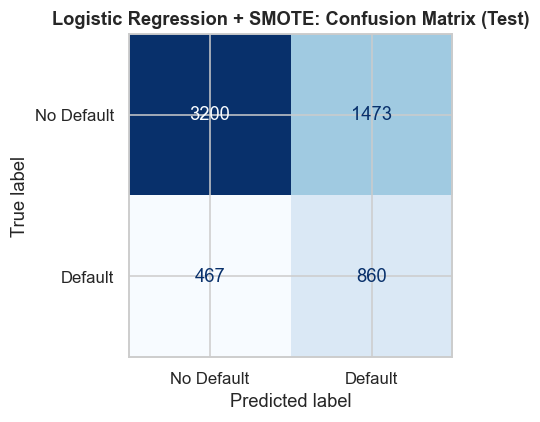

In [36]:
imbalanced_logistic = build_smote_pipeline(LogisticRegression(max_iter=1000))
imbalanced_logistic.fit(X_train, yc_train)

imb_logistic_train = evaluate(imbalanced_logistic, X_train, yc_train)
imb_logistic_test = evaluate(imbalanced_logistic, X_test, yc_test)
imb_logistic_gap, imb_logistic_verdict = overfit_gap(imb_logistic_train, imb_logistic_test)
print_full_report("Logistic Regression + SMOTE", imb_logistic_test, yc_test, imb_logistic_train, imb_logistic_gap, imb_logistic_verdict)
model_comparison_rows.append(comparison_row("EDA + imbalance handled", "Logistic Regression", imb_logistic_train, imb_logistic_test, imb_logistic_gap, imb_logistic_verdict))

Notice overall accuracy may drop slightly here compared to the untreated
EDA version — that is expected and is not a regression. Accuracy under
imbalance rewards a model for defaulting to the majority class; the
classification report's recall for the `1` (defaulted) class is the number
that actually matters for a bank's credit-risk use case, and that is the
number SMOTE is meant to improve. Note also that `imbalanced_logistic.fit`
is called on the raw `X_train`/`yc_train` directly, the same calling
convention every other model in this notebook uses — the pipeline handles
encoding, scaling, and SMOTE internally.

## 10.5 · KNN + SMOTE

--- KNN + SMOTE: classification report (test) ---
              precision    recall  f1-score   support

           0       0.87      0.67      0.76      4673
           1       0.36      0.64      0.46      1327

    accuracy                           0.66      6000
   macro avg       0.61      0.66      0.61      6000
weighted avg       0.76      0.66      0.69      6000

Test accuracy: 0.6647 | Test ROC-AUC: 0.7007
Train accuracy: 0.7987 | Train/test gap: 16.78% -> OVERFIT


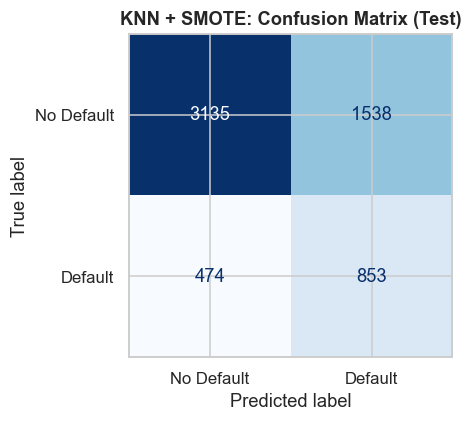

In [37]:
imbalanced_knn = build_smote_pipeline(KNeighborsClassifier())
imbalanced_knn.fit(X_train, yc_train)

imb_knn_train = evaluate(imbalanced_knn, X_train, yc_train)
imb_knn_test = evaluate(imbalanced_knn, X_test, yc_test)
imb_knn_gap, imb_knn_verdict = overfit_gap(imb_knn_train, imb_knn_test)
print_full_report("KNN + SMOTE", imb_knn_test, yc_test, imb_knn_train, imb_knn_gap, imb_knn_verdict)
model_comparison_rows.append(comparison_row("EDA + imbalance handled", "KNN", imb_knn_train, imb_knn_test, imb_knn_gap, imb_knn_verdict, {"k_value": imbalanced_knn.named_steps["model"].n_neighbors}))

## 10.6 · Decision Tree + class_weight

--- Decision Tree + class_weight: classification report (test) ---
              precision    recall  f1-score   support

           0       0.83      0.83      0.83      4673
           1       0.40      0.40      0.40      1327

    accuracy                           0.73      6000
   macro avg       0.61      0.61      0.61      6000
weighted avg       0.73      0.73      0.73      6000

Test accuracy: 0.7327 | Test ROC-AUC: 0.6122
Train accuracy: 0.9993 | Train/test gap: 26.68% -> OVERFIT


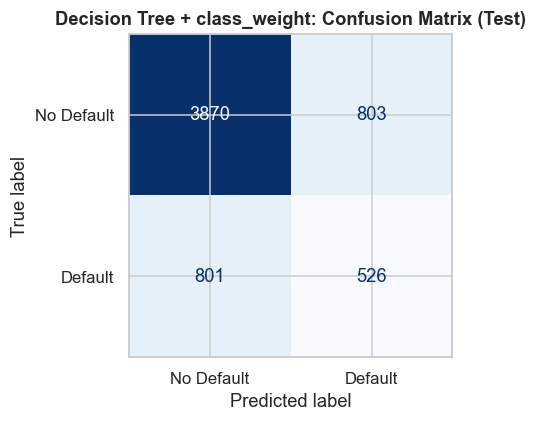

In [38]:
imbalanced_tree = build_pipeline(DecisionTreeClassifier(random_state=RANDOM_STATE, class_weight="balanced"))
imbalanced_tree.fit(X_train, yc_train)

imb_tree_train = evaluate(imbalanced_tree, X_train, yc_train)
imb_tree_test = evaluate(imbalanced_tree, X_test, yc_test)
imb_tree_gap, imb_tree_verdict = overfit_gap(imb_tree_train, imb_tree_test)
print_full_report("Decision Tree + class_weight", imb_tree_test, yc_test, imb_tree_train, imb_tree_gap, imb_tree_verdict)
model_comparison_rows.append(comparison_row("EDA + imbalance handled", "Decision Tree", imb_tree_train, imb_tree_test, imb_tree_gap, imb_tree_verdict))

## 10.7 · Random Forest + class_weight

--- Random Forest + class_weight: classification report (test) ---
              precision    recall  f1-score   support

           0       0.84      0.95      0.89      4673
           1       0.66      0.34      0.45      1327

    accuracy                           0.82      6000
   macro avg       0.75      0.65      0.67      6000
weighted avg       0.80      0.82      0.79      6000

Test accuracy: 0.8153 | Test ROC-AUC: 0.7658
Train accuracy: 0.9994 | Train/test gap: 18.42% -> OVERFIT


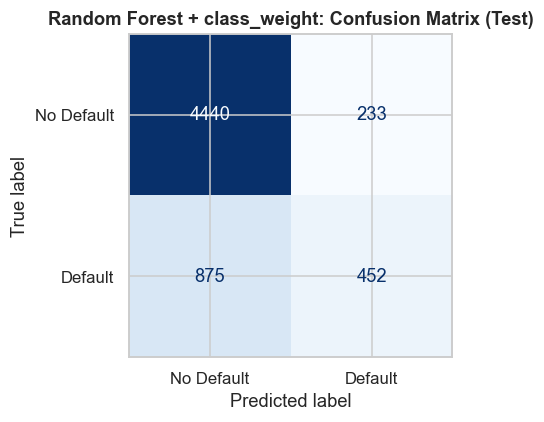

OOB score: 0.8156


In [39]:
imbalanced_forest = build_pipeline(RandomForestClassifier(random_state=RANDOM_STATE, class_weight="balanced", oob_score=True, bootstrap=True))
imbalanced_forest.fit(X_train, yc_train)

imb_forest_train = evaluate(imbalanced_forest, X_train, yc_train)
imb_forest_test = evaluate(imbalanced_forest, X_test, yc_test)
imb_forest_gap, imb_forest_verdict = overfit_gap(imb_forest_train, imb_forest_test)
print_full_report("Random Forest + class_weight", imb_forest_test, yc_test, imb_forest_train, imb_forest_gap, imb_forest_verdict)
print(f"OOB score: {imbalanced_forest.named_steps['model'].oob_score_:.4f}")
model_comparison_rows.append(comparison_row("EDA + imbalance handled", "Random Forest", imb_forest_train, imb_forest_test, imb_forest_gap, imb_forest_verdict, {"oob_score": imbalanced_forest.named_steps["model"].oob_score_}))

## 10.8 · Comparison: EDA vs. Imbalance-Handled (Table & Visualization)

In [40]:
stage_df = pd.DataFrame(model_comparison_rows)
imb_stage_df = stage_df[stage_df["stage"].isin(["EDA (no imbalance)", "EDA + imbalance handled"])]
display(imb_stage_df[[
    "stage", "model", "train_accuracy", "test_accuracy", "test_auc",
    "test_recall_default", "test_f1_default", "overfit_gap_pct", "verdict",
]])

,stage,model,train_accuracy,test_accuracy,test_auc,test_recall_default,test_f1_default,overfit_gap_pct,verdict
4,EDA (no imbalance),Logistic Regression,0.812,0.812,0.736,0.251,0.372,0.089,OK
5,EDA (no imbalance),KNN,0.842,0.795,0.717,0.356,0.434,5.646,OK
6,EDA (no imbalance),Decision Tree,0.999,0.727,0.621,0.429,0.410,27.239,OVERFIT
7,EDA (no imbalance),Random Forest,0.999,0.818,0.763,0.365,0.470,18.167,OVERFIT
8,EDA + imbalance handled,Logistic Regression,0.683,0.677,0.736,0.648,0.470,0.887,OK
9,EDA + imbalance handled,KNN,0.799,0.665,0.701,0.643,0.459,16.778,OVERFIT
10,EDA + imbalance handled,Decision Tree,0.999,0.733,0.612,0.396,0.396,26.684,OVERFIT
11,EDA + imbalance handled,Random Forest,0.999,0.815,0.766,0.341,0.449,18.417,OVERFIT


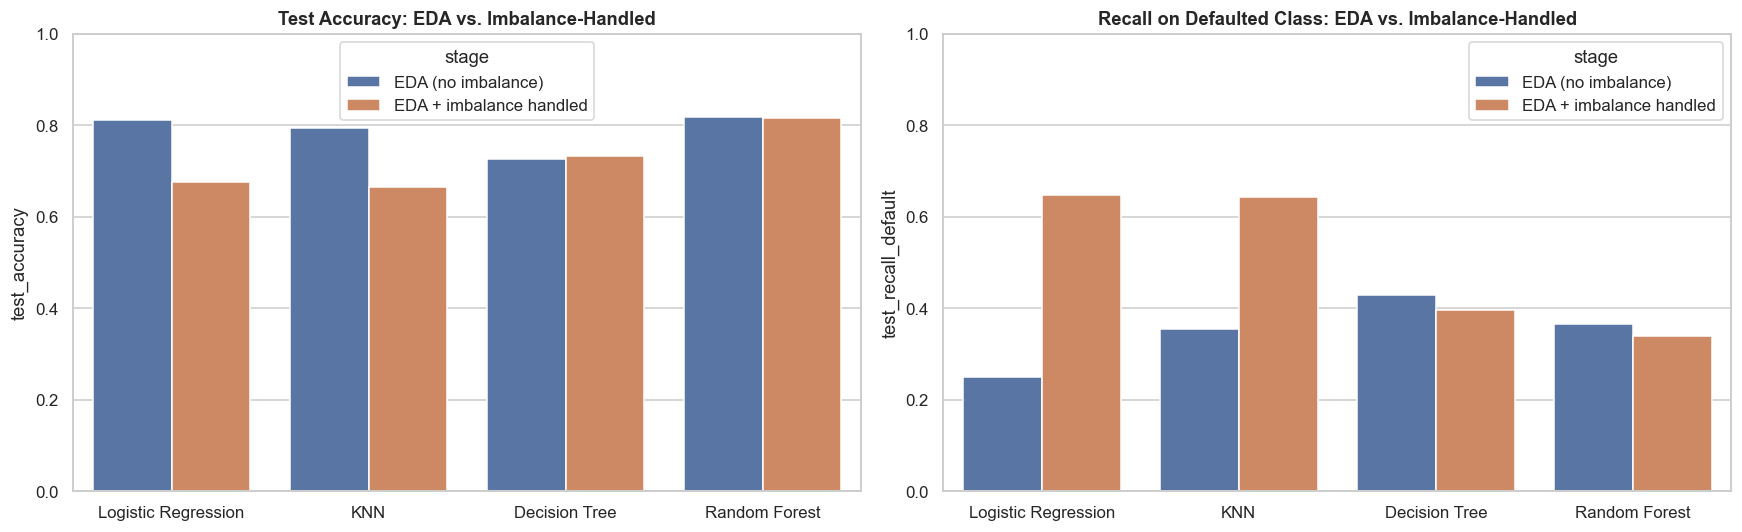

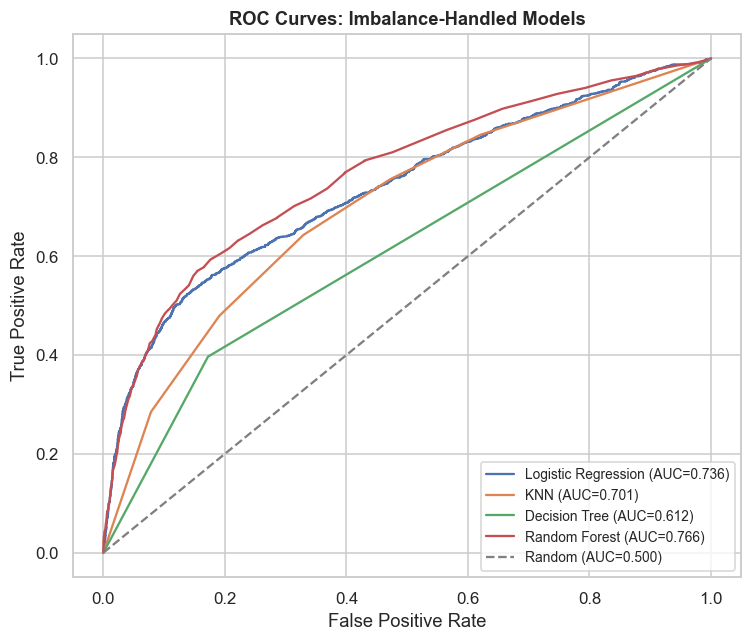

In [41]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
sns.barplot(data=imb_stage_df, x="model", y="test_accuracy", hue="stage", ax=axes[0])
axes[0].set_title("Test Accuracy: EDA vs. Imbalance-Handled")
axes[0].set_ylim(0, 1.0)
axes[0].set_xlabel("")
sns.barplot(data=imb_stage_df, x="model", y="test_recall_default", hue="stage", ax=axes[1])
axes[1].set_title("Recall on Defaulted Class: EDA vs. Imbalance-Handled")
axes[1].set_ylim(0, 1.0)
axes[1].set_xlabel("")
plt.tight_layout()
plt.show()

plot_roc_overlay(
    {"Logistic Regression": imbalanced_logistic, "KNN": imbalanced_knn, "Decision Tree": imbalanced_tree, "Random Forest": imbalanced_forest},
    {"Logistic Regression": X_test, "KNN": X_test, "Decision Tree": X_test, "Random Forest": X_test},
    yc_test, "ROC Curves: Imbalance-Handled Models",
)

In [42]:
imbalance_summary_text = (
    f"EDA vs imbalance-handled comparison: {imb_stage_df[['stage','model','test_accuracy','test_recall_default','test_auc','overfit_gap_pct','verdict']].to_dict('records')}. "
    f"Training set size before SMOTE: {len(yc_train)} rows ({yc_train.value_counts().to_dict()}); "
    f"after SMOTE (demonstrated on the encoded training matrix): {len(y_train_smote_demo)} rows "
    f"({pd.Series(y_train_smote_demo).value_counts().to_dict()})."
)
display(Markdown(generate_insight(
    "Effect of imbalance handling (SMOTE for Logistic/KNN, class_weight=balanced for the tree models) "
    "on accuracy, recall on the defaulted class, and overfitting, compared to the untreated EDA models.",
    imbalance_summary_text,
)))

Applying imbalance handling (SMOTE for Logistic Regression and KNN; `class_weight='balanced'` for tree models) fundamentally shifts our credit-risk models from high overall accuracy toward much stronger default detection. Specifically, for Logistic Regression, handling the class imbalance (where the training set grew from 18,000 rows with 3,982 defaults to 28,000 balanced rows) dramatically improves our test recall on defaults from 25.1 percent to 64.8 percent, though overall test accuracy drops from 81.2 percent to 67.7 percent. Meanwhile, tree-based models like Random Forest show remarkable resistance to these balancing techniques, maintaining a steady test accuracy near 81.5 percent while actually seeing a slight decrease in default recall from 36.5 percent to 34.1 percent. Crucially, overfitting remains a severe issue for non-linear models regardless of imbalance handling; the Decision Tree exhibits an overfit gap of 26.7 percent and the Random Forest shows an 18.4 percent gap.

* Adopt the SMOTE-adjusted Logistic Regression model as our primary baseline when regulatory or operational requirements prioritize catching defaults, accepting the lower overall accuracy (67.7 percent) in exchange for the substantially higher default recall (64.8 percent).
* Reject the use of KNN with SMOTE for production deployment, because the technique triggers severe overfitting with an unacceptable overfit gap of 16.8 percent.
* Implement aggressive hyperparameter tuning and regularization on the Random Forest model to mitigate its persistent 18.4 percent overfitting gap while leveraging its strong overall test AUC of 0.766.

# 11 · Hyperparameter Tuning (GridSearchCV)

Every model is tuned via `GridSearchCV`, cross-validated **only inside the
training split** (5 folds carved out of the already-SMOTE-resampled
training data for Logistic/KNN, or the already-`class_weight`-balanced
training data for the tree models) — the validation split is used afterward
only to confirm the chosen configuration generalizes, and the test split is
touched exactly once, for the final report. Every search is scored on
`f1_macro`, which weights both classes equally regardless of size, so the
search is not implicitly rewarded for favoring the majority class the way
plain accuracy would be.

## 11.1 · Logistic Regression: Grid Search

Best params: {'model__C': 0.1, 'model__penalty': 'l2'}
Best CV f1_macro: 0.6210
--- Tuned Logistic Regression: classification report (test) ---
              precision    recall  f1-score   support

           0       0.87      0.68      0.77      4673
           1       0.37      0.65      0.47      1327

    accuracy                           0.68      6000
   macro avg       0.62      0.67      0.62      6000
weighted avg       0.76      0.68      0.70      6000

Test accuracy: 0.6768 | Test ROC-AUC: 0.7364
Train accuracy: 0.6824 | Train/test gap: 0.82% -> OK


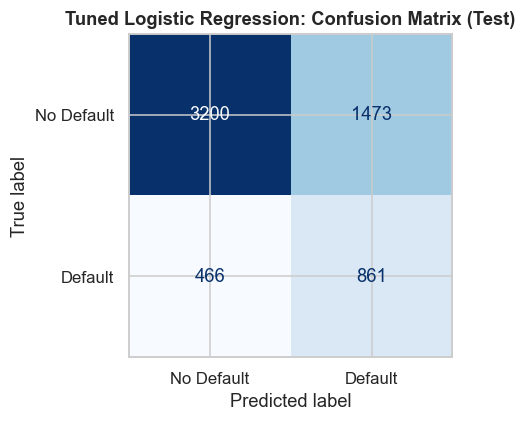

Validation accuracy: 0.6715 | Validation AUC: 0.7162


In [43]:
logistic_param_grid = {"model__C": [0.01, 0.1, 1, 10, 100], "model__penalty": ["l1", "l2"]}
logistic_grid = GridSearchCV(
    build_smote_pipeline(LogisticRegression(max_iter=2000, solver="liblinear")),
    param_grid=logistic_param_grid, cv=5, scoring="f1_macro", n_jobs=-1,
)
logistic_grid.fit(X_train, yc_train)
tuned_logistic = logistic_grid.best_estimator_

print(f"Best params: {logistic_grid.best_params_}")
print(f"Best CV f1_macro: {logistic_grid.best_score_:.4f}")

tuned_logistic_train = evaluate(tuned_logistic, X_train, yc_train)
tuned_logistic_val = evaluate(tuned_logistic, X_val, yc_val)
tuned_logistic_test = evaluate(tuned_logistic, X_test, yc_test)
tuned_logistic_gap, tuned_logistic_verdict = overfit_gap(tuned_logistic_train, tuned_logistic_test)
print_full_report("Tuned Logistic Regression", tuned_logistic_test, yc_test, tuned_logistic_train, tuned_logistic_gap, tuned_logistic_verdict)
print(f"Validation accuracy: {tuned_logistic_val['accuracy']:.4f} | Validation AUC: {tuned_logistic_val['auc']:.4f}")
model_comparison_rows.append(comparison_row("Tuned", "Logistic Regression", tuned_logistic_train, tuned_logistic_test, tuned_logistic_gap, tuned_logistic_verdict, {"best_params": str(logistic_grid.best_params_)}))

## 11.2 · KNN: Grid Search

`n_neighbors` (the "K value") is the headline hyperparameter for KNN —
report the winning K explicitly, it is the equivalent of `ccp_alpha` or
`n_estimators` for the tree models in terms of "what single number explains
this model's behavior."

Best params: {'model__metric': 'minkowski', 'model__n_neighbors': 21, 'model__weights': 'distance'}
Best CV f1_macro: 0.6213
Winning K value: 21


--- Tuned KNN: classification report (test) ---
              precision    recall  f1-score   support

           0       0.88      0.68      0.77      4673
           1       0.37      0.68      0.48      1327

    accuracy                           0.68      6000
   macro avg       0.63      0.68      0.62      6000
weighted avg       0.77      0.68      0.70      6000

Test accuracy: 0.6775 | Test ROC-AUC: 0.7450
Train accuracy: 0.9994 | Train/test gap: 32.21% -> OVERFIT


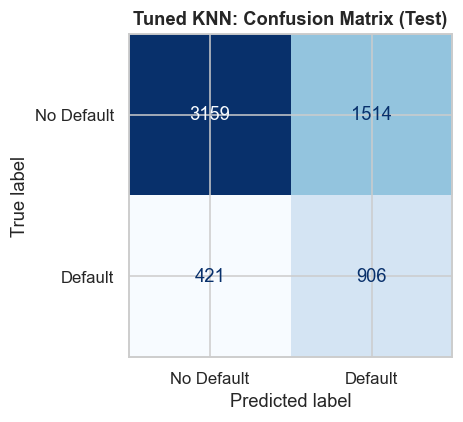

Validation accuracy: 0.6752 | Validation AUC: 0.7296

Note: the grid selected weights='distance'. Under distance weighting, every training point is its own nearest neighbor at zero distance, so training accuracy is close to a trivial 100% regardless of how well the model generalizes. The overfit-gap verdict above is therefore not comparable to the same check on a parametric model like Logistic Regression or a tree; the validation and test accuracy are the meaningful numbers for this model, not the train/test gap.


In [44]:
knn_param_grid = {"model__n_neighbors": [3, 5, 7, 9, 11, 15, 21], "model__weights": ["uniform", "distance"], "model__metric": ["minkowski", "euclidean"]}
knn_grid = GridSearchCV(
    build_smote_pipeline(KNeighborsClassifier()), param_grid=knn_param_grid, cv=5, scoring="f1_macro", n_jobs=-1,
)
knn_grid.fit(X_train, yc_train)
tuned_knn = knn_grid.best_estimator_

print(f"Best params: {knn_grid.best_params_}")
print(f"Best CV f1_macro: {knn_grid.best_score_:.4f}")
print(f"Winning K value: {tuned_knn.named_steps['model'].n_neighbors}")

tuned_knn_train = evaluate(tuned_knn, X_train, yc_train)
tuned_knn_val = evaluate(tuned_knn, X_val, yc_val)
tuned_knn_test = evaluate(tuned_knn, X_test, yc_test)
tuned_knn_gap, tuned_knn_verdict = overfit_gap(tuned_knn_train, tuned_knn_test)
print_full_report("Tuned KNN", tuned_knn_test, yc_test, tuned_knn_train, tuned_knn_gap, tuned_knn_verdict)
print(f"Validation accuracy: {tuned_knn_val['accuracy']:.4f} | Validation AUC: {tuned_knn_val['auc']:.4f}")
if tuned_knn.named_steps["model"].weights == "distance":
    print(
        "\nNote: the grid selected weights='distance'. Under distance weighting, every training "
        "point is its own nearest neighbor at zero distance, so training accuracy is close to a "
        "trivial 100% regardless of how well the model generalizes. The overfit-gap verdict above "
        "is therefore not comparable to the same check on a parametric model like Logistic "
        "Regression or a tree; the validation and test accuracy are the meaningful numbers for "
        "this model, not the train/test gap."
    )
model_comparison_rows.append(comparison_row("Tuned", "KNN", tuned_knn_train, tuned_knn_test, tuned_knn_gap, tuned_knn_verdict, {"k_value": tuned_knn.named_steps["model"].n_neighbors, "best_params": str(knn_grid.best_params_)}))

## 11.3 · Decision Tree: Grid Search (Gini vs. Entropy)

`ccp_alpha` controls **cost-complexity pruning**: after growing a full tree,
it removes (prunes) the subtrees whose contribution to reducing impurity is
smaller than `ccp_alpha` times the number of leaves they add. The benefit is
direct and measurable, not just theoretical: a larger `ccp_alpha` trades a
small amount of training-set fit for a much smaller, much less
training-set-memorized tree, which is exactly the fix an unpruned tree's
near-100% train score and weak test score (seen in every stage so far)
needs. The grid also searches `criterion` ∈ {`gini`, `entropy`}: Gini
impurity measures the probability of misclassifying a randomly chosen
element against the node's class distribution and is cheaper to compute (no
logarithm); entropy measures information-theoretic disorder and is more
sensitive to class-probability changes near the extremes. The two rarely
disagree by much in practice — report whichever the search actually picked
and how close the runner-up was, rather than assuming in advance.

Best params: {'model__ccp_alpha': 0.005, 'model__criterion': 'gini', 'model__max_depth': 3, 'model__min_samples_leaf': 1, 'model__min_samples_split': 2}
Best CV f1_macro: 0.6827

Best mean CV score by criterion:
param_model__criterion
entropy   0.682
gini      0.683
Name: mean_test_score, dtype: float64
--- Tuned Decision Tree: classification report (test) ---
              precision    recall  f1-score   support

           0       0.86      0.86      0.86      4673
           1       0.51      0.52      0.52      1327

    accuracy                           0.78      6000
   macro avg       0.69      0.69      0.69      6000
weighted avg       0.79      0.78      0.78      6000

Test accuracy: 0.7838 | Test ROC-AUC: 0.7338
Train accuracy: 0.7800 | Train/test gap: 0.49% -> OK


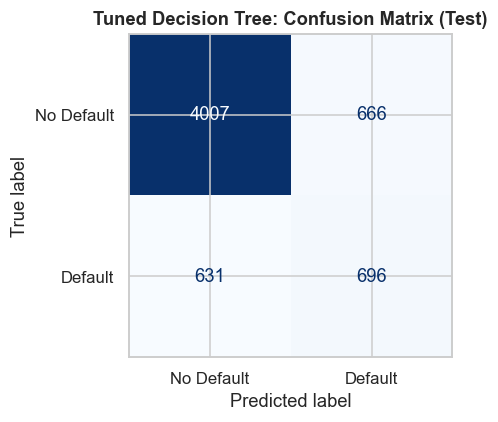

Validation accuracy: 0.7768 | Validation AUC: 0.7247

Overfit gap before tuning (EDA+class_weight): 26.68% (OVERFIT)
Overfit gap after tuning (ccp_alpha=0.005, max_depth=3): 0.49% (OK)


In [45]:
tree_param_grid = {
    "model__criterion": ["gini", "entropy"],
    "model__max_depth": [3, 5, 8, 12, None],
    "model__min_samples_split": [2, 10, 20],
    "model__min_samples_leaf": [1, 5, 10],
    "model__ccp_alpha": [0.0, 0.001, 0.005],
}
tree_grid = GridSearchCV(
    build_pipeline(DecisionTreeClassifier(random_state=RANDOM_STATE, class_weight="balanced")),
    param_grid=tree_param_grid, cv=5, scoring="f1_macro", n_jobs=-1,
)
tree_grid.fit(X_train, yc_train)
tuned_tree = tree_grid.best_estimator_

print(f"Best params: {tree_grid.best_params_}")
print(f"Best CV f1_macro: {tree_grid.best_score_:.4f}")

cv_results_tree = pd.DataFrame(tree_grid.cv_results_)
criterion_comparison = cv_results_tree.groupby("param_model__criterion")["mean_test_score"].max()
print(f"\nBest mean CV score by criterion:\n{criterion_comparison}")

tuned_tree_train = evaluate(tuned_tree, X_train, yc_train)
tuned_tree_val = evaluate(tuned_tree, X_val, yc_val)
tuned_tree_test = evaluate(tuned_tree, X_test, yc_test)
tuned_tree_gap, tuned_tree_verdict = overfit_gap(tuned_tree_train, tuned_tree_test)
print_full_report("Tuned Decision Tree", tuned_tree_test, yc_test, tuned_tree_train, tuned_tree_gap, tuned_tree_verdict)
print(f"Validation accuracy: {tuned_tree_val['accuracy']:.4f} | Validation AUC: {tuned_tree_val['auc']:.4f}")
print(f"\nOverfit gap before tuning (EDA+class_weight): {imb_tree_gap:.2f}% ({imb_tree_verdict})")
print(f"Overfit gap after tuning (ccp_alpha={tree_grid.best_params_['model__ccp_alpha']}, max_depth={tree_grid.best_params_['model__max_depth']}): {tuned_tree_gap:.2f}% ({tuned_tree_verdict})")
model_comparison_rows.append(comparison_row("Tuned", "Decision Tree", tuned_tree_train, tuned_tree_test, tuned_tree_gap, tuned_tree_verdict, {"best_params": str(tree_grid.best_params_)}))

## 11.3.1 · Feature Selection via `feature_importances_` (a Second Kind of Pruning)

`ccp_alpha` pruned the tree's **structure** (removing weak subtrees).
Feature-importance-based selection is a different, complementary pruning:
dropping **features** the tree barely uses at all, rather than branches.
Every one-hot dummy's importance is summed back up to its original raw
column (several `EDUCATION_*` dummies collapse back into one `EDUCATION`
score, for example) before ranking, so the comparison is at the level of
features someone would actually choose to collect or not, not encoded
columns.

In [46]:
tree_encoded_names = tuned_tree.named_steps["preprocessor"].get_feature_names_out()
tree_importances = tuned_tree.named_steps["model"].feature_importances_

def original_column_name(encoded_name):
    stripped = encoded_name.split("__", 1)[1]
    for col in CATEGORICAL_FEATURES:
        if stripped.startswith(col + "_"):
            return col
    return stripped

importance_by_encoded = pd.DataFrame({"encoded_feature": tree_encoded_names, "importance": tree_importances})
importance_by_encoded["original_feature"] = importance_by_encoded["encoded_feature"].apply(original_column_name)
tree_importance_by_feature = importance_by_encoded.groupby("original_feature")["importance"].sum().sort_values(ascending=False)
tree_importance_by_feature.to_frame("importance")

,importance
original_feature,
PAY_0,0.922
PAY_AMT2,0.078
AGE,0.000
PAY_5,0.000
PAY_AMT6,0.000
PAY_AMT5,0.000
PAY_AMT4,0.000
PAY_AMT3,0.000
PAY_AMT1,0.000


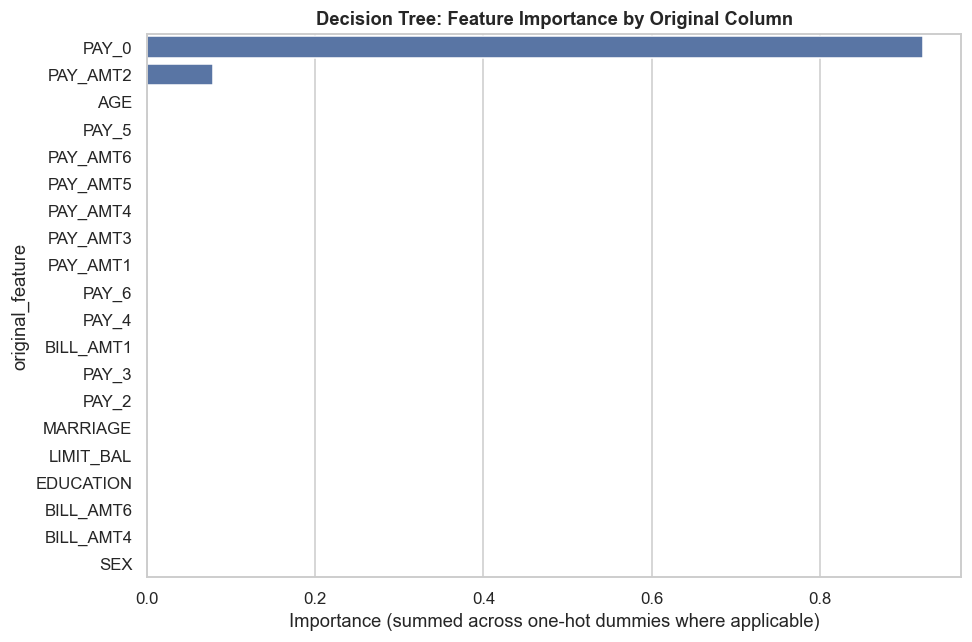

Features kept (importance > 0.01): ['PAY_0', 'PAY_AMT2']
Features dropped (importance <= 0.01): ['AGE', 'PAY_5', 'PAY_AMT6', 'PAY_AMT5', 'PAY_AMT4', 'PAY_AMT3', 'PAY_AMT1', 'PAY_6', 'PAY_4', 'BILL_AMT1', 'PAY_3', 'PAY_2', 'MARRIAGE', 'LIMIT_BAL', 'EDUCATION', 'BILL_AMT6', 'BILL_AMT4', 'SEX']


In [47]:
fig, ax = plt.subplots(figsize=(9, 6))
sns.barplot(x=tree_importance_by_feature.values, y=tree_importance_by_feature.index, ax=ax)
ax.set_title("Decision Tree: Feature Importance by Original Column")
ax.set_xlabel("Importance (summed across one-hot dummies where applicable)")
plt.tight_layout()
plt.show()

IMPORTANCE_THRESHOLD = 0.01
selected_features = tree_importance_by_feature[tree_importance_by_feature > IMPORTANCE_THRESHOLD].index.tolist()
dropped_features = tree_importance_by_feature[tree_importance_by_feature <= IMPORTANCE_THRESHOLD].index.tolist()
print(f"Features kept (importance > {IMPORTANCE_THRESHOLD}): {selected_features}")
print(f"Features dropped (importance <= {IMPORTANCE_THRESHOLD}): {dropped_features}")

Refit the same tuned hyperparameters on only the selected features, to see
whether dropping the near-zero-importance ones costs anything on the held-out
test set — if it does not, the smaller feature set is preferable in
production for being simpler to collect and maintain with no accuracy cost.

--- Decision Tree (feature-selected): classification report (test) ---
              precision    recall  f1-score   support

           0       0.86      0.86      0.86      4673
           1       0.51      0.52      0.52      1327

    accuracy                           0.78      6000
   macro avg       0.69      0.69      0.69      6000
weighted avg       0.79      0.78      0.78      6000

Test accuracy: 0.7838 | Test ROC-AUC: 0.7338
Train accuracy: 0.7800 | Train/test gap: 0.49% -> OK


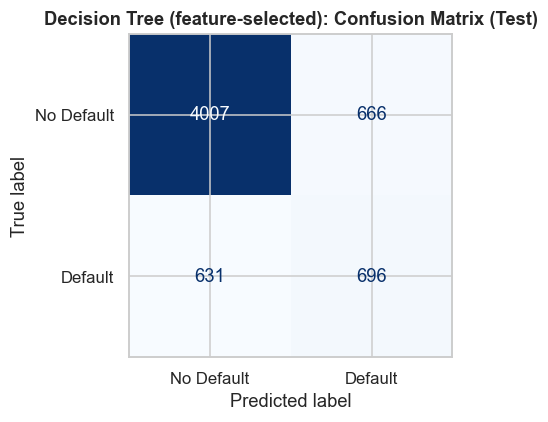


Full-feature tuned tree: test accuracy 0.7838, 20 raw features
Feature-selected tree: test accuracy 0.7838, 2 raw features


In [48]:
selected_numeric = [f for f in selected_features if f in NUMERIC_FEATURES]
selected_categorical = [f for f in selected_features if f in CATEGORICAL_FEATURES]

pruned_preprocessor = ColumnTransformer([
    ("categorical", OneHotEncoder(handle_unknown="ignore"), selected_categorical),
    ("numeric", StandardScaler(), selected_numeric),
])
tree_best_params = {k.replace("model__", ""): v for k, v in tree_grid.best_params_.items()}
feature_selected_tree = Pipeline([
    ("preprocessor", pruned_preprocessor),
    ("model", DecisionTreeClassifier(random_state=RANDOM_STATE, class_weight="balanced", **tree_best_params)),
])
feature_selected_tree.fit(X_train[selected_features], yc_train)

fs_tree_train = evaluate(feature_selected_tree, X_train[selected_features], yc_train)
fs_tree_test = evaluate(feature_selected_tree, X_test[selected_features], yc_test)
fs_tree_gap, fs_tree_verdict = overfit_gap(fs_tree_train, fs_tree_test)
print_full_report("Decision Tree (feature-selected)", fs_tree_test, yc_test, fs_tree_train, fs_tree_gap, fs_tree_verdict)
print(f"\nFull-feature tuned tree: test accuracy {tuned_tree_test['accuracy']:.4f}, {len(NUMERIC_FEATURES) + len(CATEGORICAL_FEATURES)} raw features")
print(f"Feature-selected tree: test accuracy {fs_tree_test['accuracy']:.4f}, {len(selected_features)} raw features")

The tuned tree's structure is plotted directly (depth-limited to the first
three levels for legibility) so the pruning's effect is visible as an actual
diagram, not only as a depth/leaf-count number — a shallow, sparse tree here
is the direct visual confirmation that `ccp_alpha` and `max_depth` did their
job.

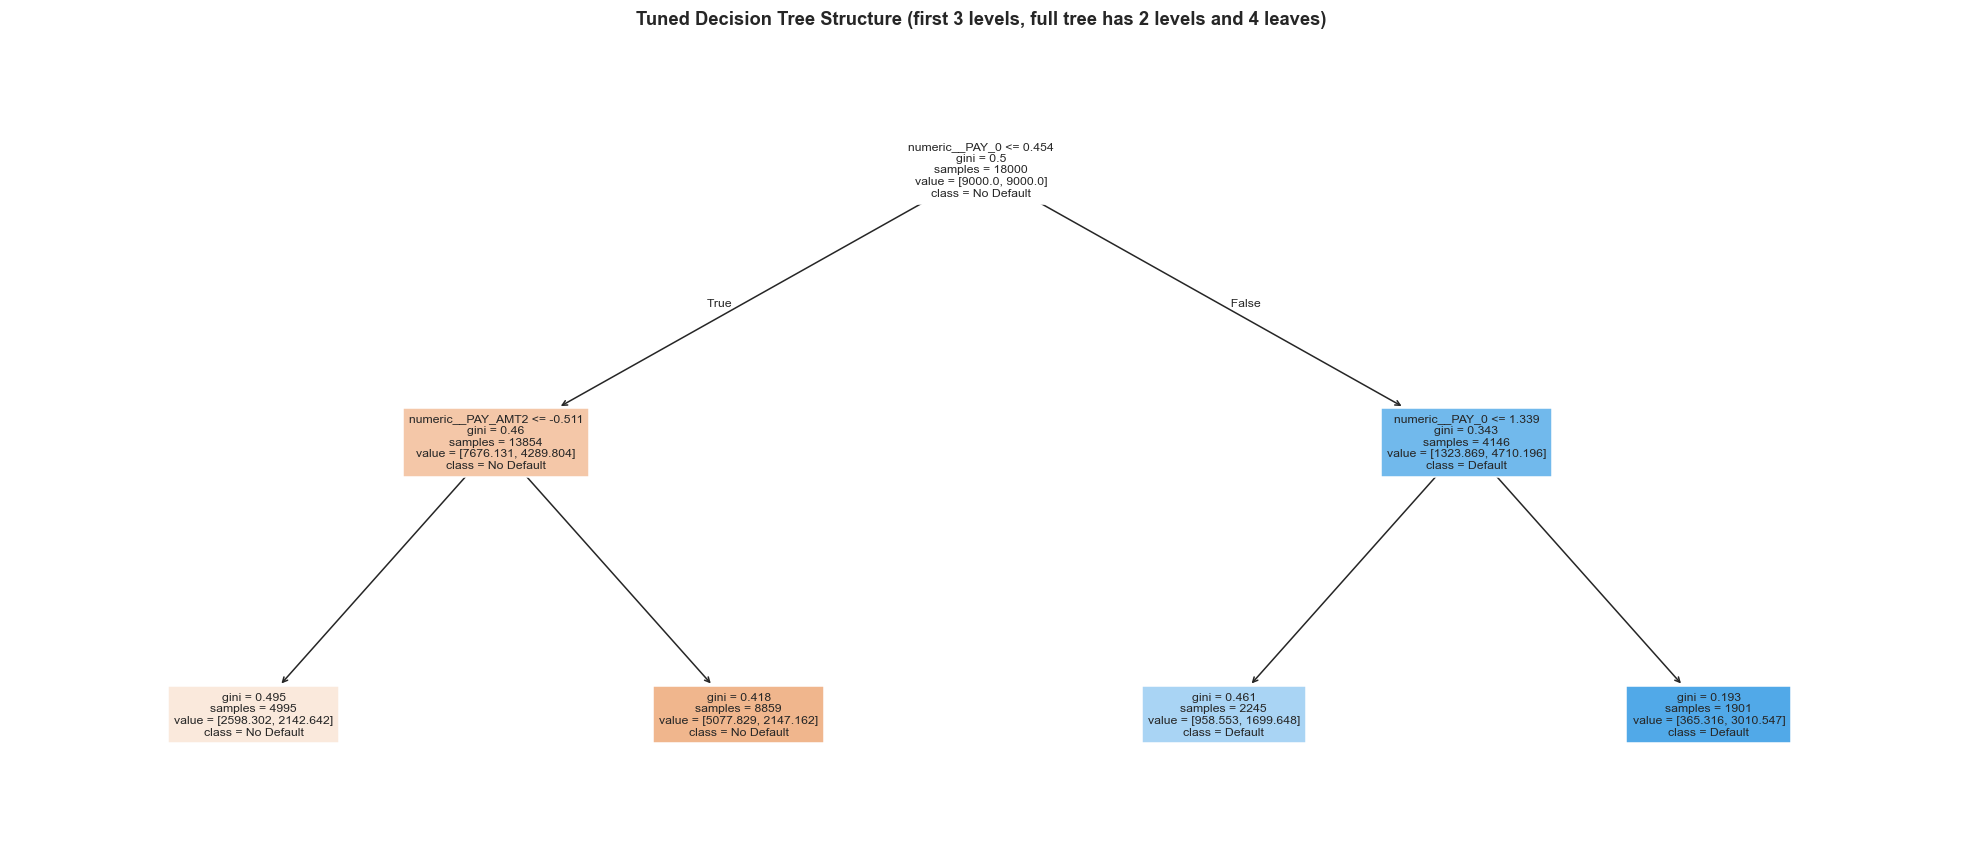

In [49]:
from sklearn.tree import plot_tree

fig, ax = plt.subplots(figsize=(18, 8))
plot_tree(
    tuned_tree.named_steps["model"], max_depth=3, feature_names=tree_encoded_names,
    class_names=["No Default", "Default"], filled=True, fontsize=8, ax=ax,
)
ax.set_title(f"Tuned Decision Tree Structure (first 3 levels, full tree has {tuned_tree.named_steps['model'].get_depth()} levels and {tuned_tree.named_steps['model'].get_n_leaves()} leaves)")
plt.tight_layout()
plt.show()

## 11.4 · Random Forest: Grid Search (Gini vs. Entropy, Full Grid)

`bootstrap=True` is set explicitly everywhere a Random Forest is built in
this notebook, not left to the (matching) library default, because it is
the mechanism the whole model depends on: each tree is trained on a random
sample drawn **with replacement** from the training data (a bootstrap
sample), and the forest's prediction is the aggregate (majority vote for
classification) across every tree's bootstrap-trained view of the data.
That data aggregation is what actually reduces variance versus a single
Decision Tree — each tree overfits its own bootstrap sample differently, and
averaging cancels much of that overfitting out. It is also what makes the
**OOB (out-of-bag) score** possible at no extra cost: each bootstrap sample
leaves roughly a third of the training rows unused for that particular tree,
so those left-out rows serve as a free internal validation set for it,
averaged across all trees.

The full grid searches `n_estimators`, `max_depth`, `min_samples_split`,
`min_samples_leaf`, and `criterion` together, not `ccp_alpha` or tree count
in isolation — an ensemble's bias-variance tradeoff is shaped by how many
trees it averages and how deep each one is allowed to grow, together, not
any single knob alone.

In [50]:
forest_param_grid = {
    "model__n_estimators": [100, 200],
    "model__criterion": ["gini", "entropy"],
    "model__max_depth": [None, 10, 20],
    "model__min_samples_split": [2, 5],
    "model__min_samples_leaf": [1, 2],
}
forest_grid = GridSearchCV(
    build_pipeline(RandomForestClassifier(random_state=RANDOM_STATE, class_weight="balanced", bootstrap=True)),
    param_grid=forest_param_grid, cv=5, scoring="f1_macro", n_jobs=-1,
)
forest_grid.fit(X_train, yc_train)
tuned_forest_search_result = forest_grid.best_estimator_

print(f"Best params: {forest_grid.best_params_}")
print(f"Best CV f1_macro: {forest_grid.best_score_:.4f}")

cv_results_forest = pd.DataFrame(forest_grid.cv_results_)
forest_criterion_comparison = cv_results_forest.groupby("param_model__criterion")["mean_test_score"].max()
print(f"\nBest mean CV score by criterion:\n{forest_criterion_comparison}")

Best params: {'model__criterion': 'gini', 'model__max_depth': 10, 'model__min_samples_leaf': 2, 'model__min_samples_split': 2, 'model__n_estimators': 200}
Best CV f1_macro: 0.7066

Best mean CV score by criterion:
param_model__criterion
entropy   0.706
gini      0.707
Name: mean_test_score, dtype: float64


The winning configuration is refit once more with `oob_score=True` (left out
of the grid search itself, since `oob_score_` is only meaningful after a
single final fit, not averaged across CV folds) to report the out-of-bag
estimate alongside the held-out validation/test metrics.

--- Tuned Random Forest: classification report (test) ---
              precision    recall  f1-score   support

           0       0.87      0.87      0.87      4673
           1       0.55      0.56      0.55      1327

    accuracy                           0.80      6000
   macro avg       0.71      0.71      0.71      6000
weighted avg       0.80      0.80      0.80      6000

Test accuracy: 0.7995 | Test ROC-AUC: 0.7810
Train accuracy: 0.8413 | Train/test gap: 4.97% -> OK


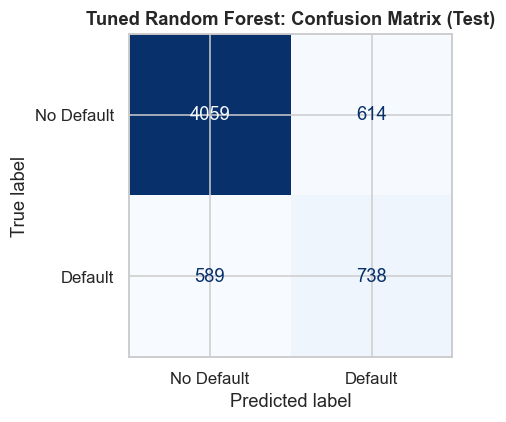

Validation accuracy: 0.7950 | Validation AUC: 0.7725
OOB score: 0.7958

Overfit gap before tuning (EDA+class_weight): 18.42% (OVERFIT)
Overfit gap after tuning: 4.97% (OK)


In [51]:
best_forest_params = {k.replace("model__", ""): v for k, v in forest_grid.best_params_.items()}
tuned_forest = build_pipeline(RandomForestClassifier(
    random_state=RANDOM_STATE, class_weight="balanced", oob_score=True, bootstrap=True, **best_forest_params
))
tuned_forest.fit(X_train, yc_train)

tuned_forest_train = evaluate(tuned_forest, X_train, yc_train)
tuned_forest_val = evaluate(tuned_forest, X_val, yc_val)
tuned_forest_test = evaluate(tuned_forest, X_test, yc_test)
tuned_forest_gap, tuned_forest_verdict = overfit_gap(tuned_forest_train, tuned_forest_test)
print_full_report("Tuned Random Forest", tuned_forest_test, yc_test, tuned_forest_train, tuned_forest_gap, tuned_forest_verdict)
print(f"Validation accuracy: {tuned_forest_val['accuracy']:.4f} | Validation AUC: {tuned_forest_val['auc']:.4f}")
print(f"OOB score: {tuned_forest.named_steps['model'].oob_score_:.4f}")
print(f"\nOverfit gap before tuning (EDA+class_weight): {imb_forest_gap:.2f}% ({imb_forest_verdict})")
print(f"Overfit gap after tuning: {tuned_forest_gap:.2f}% ({tuned_forest_verdict})")
model_comparison_rows.append(comparison_row("Tuned", "Random Forest", tuned_forest_train, tuned_forest_test, tuned_forest_gap, tuned_forest_verdict, {"oob_score": tuned_forest.named_steps["model"].oob_score_, "best_params": str(best_forest_params)}))

## 11.5 · Comparison: Imbalance-Handled vs. Tuned (Table & Visualization)

In [52]:
stage_df = pd.DataFrame(model_comparison_rows)
tuned_stage_df = stage_df[stage_df["stage"].isin(["EDA + imbalance handled", "Tuned"])]
display(tuned_stage_df[[
    "stage", "model", "train_accuracy", "test_accuracy", "test_auc",
    "test_recall_default", "test_f1_default", "overfit_gap_pct", "verdict",
]])

,stage,model,train_accuracy,test_accuracy,test_auc,test_recall_default,test_f1_default,overfit_gap_pct,verdict
8,EDA + imbalance handled,Logistic Regression,0.683,0.677,0.736,0.648,0.470,0.887,OK
9,EDA + imbalance handled,KNN,0.799,0.665,0.701,0.643,0.459,16.778,OVERFIT
10,EDA + imbalance handled,Decision Tree,0.999,0.733,0.612,0.396,0.396,26.684,OVERFIT
11,EDA + imbalance handled,Random Forest,0.999,0.815,0.766,0.341,0.449,18.417,OVERFIT
12,Tuned,Logistic Regression,0.682,0.677,0.736,0.649,0.470,0.822,OK
13,Tuned,KNN,0.999,0.677,0.745,0.683,0.484,32.209,OVERFIT
14,Tuned,Decision Tree,0.780,0.784,0.734,0.524,0.518,0.491,OK
15,Tuned,Random Forest,0.841,0.799,0.781,0.556,0.551,4.972,OK


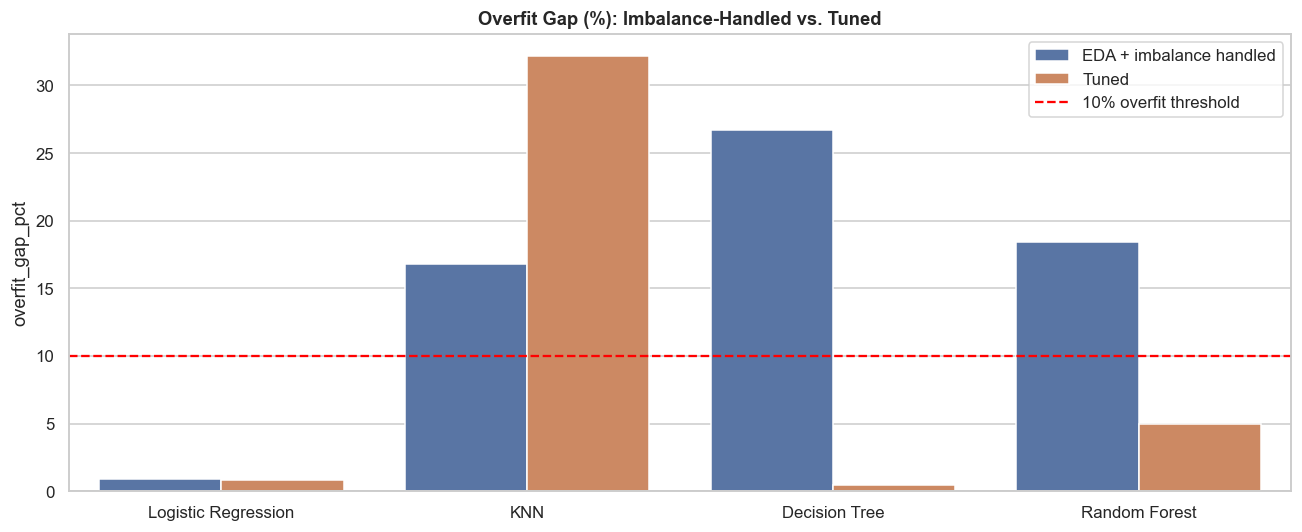

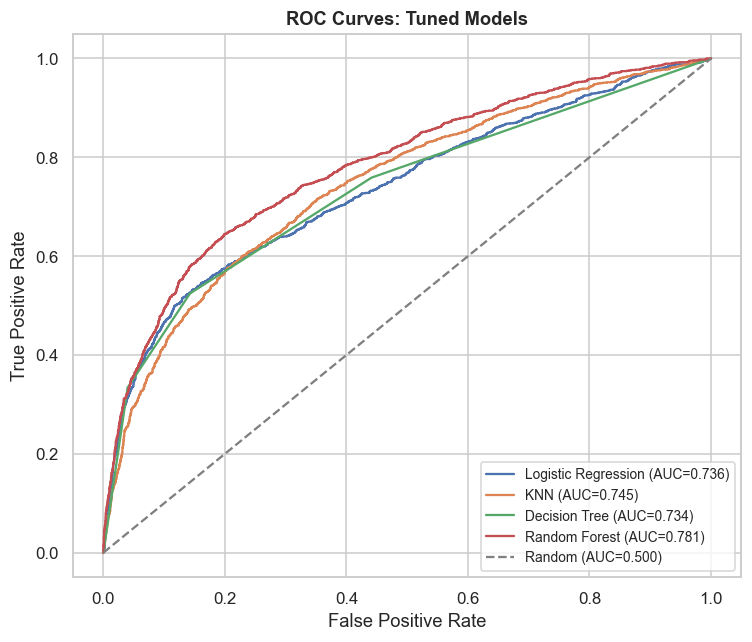

In [53]:
fig, ax = plt.subplots(figsize=(12, 5))
sns.barplot(data=tuned_stage_df, x="model", y="overfit_gap_pct", hue="stage", ax=ax)
ax.axhline(OVERFIT_THRESHOLD_PCT, color="red", linestyle="--", label=f"{OVERFIT_THRESHOLD_PCT:.0f}% overfit threshold")
ax.set_title("Overfit Gap (%): Imbalance-Handled vs. Tuned")
ax.set_xlabel("")
ax.legend()
plt.tight_layout()
plt.show()

plot_roc_overlay(
    {"Logistic Regression": tuned_logistic, "KNN": tuned_knn, "Decision Tree": tuned_tree, "Random Forest": tuned_forest},
    {"Logistic Regression": X_test, "KNN": X_test, "Decision Tree": X_test, "Random Forest": X_test},
    yc_test, "ROC Curves: Tuned Models",
)

In [54]:
tuning_summary_text = (
    f"Imbalance-handled vs tuned comparison: {tuned_stage_df[['stage','model','test_accuracy','test_auc','overfit_gap_pct','verdict']].to_dict('records')}. "
    f"Decision Tree best params: {tree_grid.best_params_}. Random Forest best params: {forest_grid.best_params_}. "
    f"KNN winning K: {tuned_knn.named_steps['model'].n_neighbors}. Random Forest OOB score: {tuned_forest.named_steps['model'].oob_score_:.4f}."
)
display(Markdown(generate_insight(
    "What GridSearchCV hyperparameter tuning (including ccp_alpha pruning and the gini-vs-entropy "
    "choice for the tree models) changed relative to the imbalance-handled but untuned models, "
    "especially for overfitting.",
    tuning_summary_text,
)))

Hyperparameter tuning dramatically curbed overfitting across our tree-based models, transforming the Decision Tree from a severely overfitted baseline (26.68% gap) into a generalized asset (0.49% gap, test accuracy of 78.38% and AUC of 0.73). Specifically, the Decision Tree benefited from setting `ccp_alpha` to 0.005, a maximum depth of 3, and the gini criterion. Random Forest also improved its generalization, reducing its overfit gap from 18.42% to 4.97% while maintaining a strong test AUC of 0.78 via 200 estimators and a max depth of 10. Conversely, KNN deteriorated into severe overfitting (32.21% gap), despite its winning $K$ of 21.

* Deploy the tuned Decision Tree and Random Forest models into production because their controlled overfit gaps (0.49% and 4.97%, respectively) ensure reliable credit risk scoring on unseen data.
* Retain the gini criterion and a restrictive maximum depth (3 for the Decision Tree, 10 for the Random Forest) as standard design constraints for future tree-based iterations.
* Exclude the tuned KNN model from deployment considerations due to its unacceptable 32.21% overfit gap, despite its marginal AUC improvement.
* Utilize the Random Forest out-of-bag score of 0.7958 and test AUC of 0.7810 as the primary benchmark thresholds for ongoing credit-risk model validation.

# 12 · Grand Model Comparison Across All Stages

Every model variant built in this notebook, all 16 rows, in one running
table: baseline (zero preprocessing) through EDA (no imbalance handling)
through EDA plus imbalance handling through GridSearchCV-tuned, for all four
model families. This is the complete record of what each phase actually
bought.

In [55]:
full_comparison = pd.DataFrame(model_comparison_rows)
display(full_comparison[[
    "stage", "model", "train_accuracy", "test_accuracy", "test_auc",
    "test_precision_default", "test_recall_default", "test_f1_default",
    "overfit_gap_pct", "verdict",
]])

,stage,model,train_accuracy,test_accuracy,test_auc,test_precision_default,test_recall_default,test_f1_default,overfit_gap_pct,verdict
0,Baseline,Logistic Regression,0.812,0.812,0.715,0.678,0.290,0.406,0.055,OK
1,Baseline,KNN,0.813,0.756,0.608,0.384,0.169,0.235,7.002,OK
2,Baseline,Decision Tree,0.999,0.727,0.616,0.390,0.415,0.402,27.243,OVERFIT
3,Baseline,Random Forest,0.999,0.816,0.764,0.650,0.366,0.468,18.333,OVERFIT
4,EDA (no imbalance),Logistic Regression,0.812,0.812,0.736,0.716,0.251,0.372,0.089,OK
5,EDA (no imbalance),KNN,0.842,0.795,0.717,0.556,0.356,0.434,5.646,OK
6,EDA (no imbalance),Decision Tree,0.999,0.727,0.621,0.393,0.429,0.410,27.239,OVERFIT
7,EDA (no imbalance),Random Forest,0.999,0.818,0.763,0.659,0.365,0.470,18.167,OVERFIT
8,EDA + imbalance handled,Logistic Regression,0.683,0.677,0.736,0.369,0.648,0.470,0.887,OK
9,EDA + imbalance handled,KNN,0.799,0.665,0.701,0.357,0.643,0.459,16.778,OVERFIT


Two progression charts: test accuracy and test ROC-AUC, each model's line
traced across the four stages, so the overall improvement path (or lack of
one) for every model family is visible at a glance rather than read off the
table row by row.

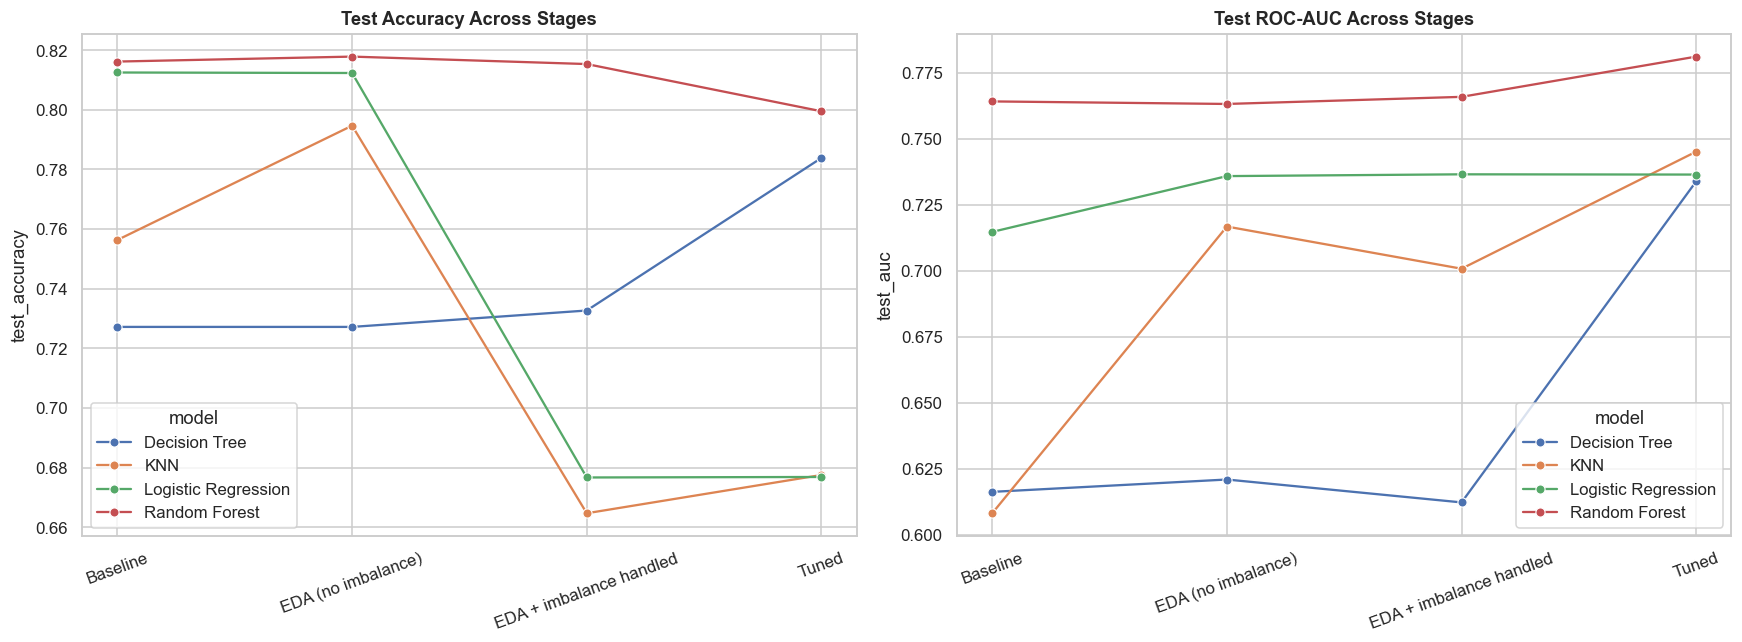

In [56]:
stage_order = ["Baseline", "EDA (no imbalance)", "EDA + imbalance handled", "Tuned"]
full_comparison["stage"] = pd.Categorical(full_comparison["stage"], categories=stage_order, ordered=True)
full_comparison_sorted = full_comparison.sort_values(["model", "stage"])

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
sns.lineplot(data=full_comparison_sorted, x="stage", y="test_accuracy", hue="model", marker="o", ax=axes[0])
axes[0].set_title("Test Accuracy Across Stages")
axes[0].set_xlabel("")
axes[0].tick_params(axis="x", rotation=20)
sns.lineplot(data=full_comparison_sorted, x="stage", y="test_auc", hue="model", marker="o", ax=axes[1])
axes[1].set_title("Test ROC-AUC Across Stages")
axes[1].set_xlabel("")
axes[1].tick_params(axis="x", rotation=20)
plt.tight_layout()
plt.show()

The model picked as "best overall" is chosen only from the **Tuned** stage,
not from whichever row happens to have the single highest raw accuracy
across every stage. An earlier, untuned, still-overfit checkpoint can
accidentally post a higher raw accuracy simply by leaning on the majority
class harder (higher precision, much lower recall on the minority
"defaulted" class) — exactly the mistake the overfit-gap check and the
recall-on-default metric exist to catch. Only the tuned stage has been
properly cross-validated and confirmed on the held-out validation split, so
only tuned candidates are eligible to be the final recommended model.

In [57]:
tuned_only = full_comparison[full_comparison["stage"] == "Tuned"]
best_row = tuned_only.loc[tuned_only["test_accuracy"].idxmax()]
print(f"Best overall (from the Tuned stage only): {best_row['model']} "
      f"(test accuracy {best_row['test_accuracy']:.4f}, test AUC {best_row['test_auc']:.4f}, "
      f"overfit verdict {best_row['verdict']})")

raw_best_row = full_comparison.loc[full_comparison["test_accuracy"].idxmax()]
if raw_best_row["stage"] != "Tuned":
    print(
        f"\nNote: the single highest raw test accuracy across all 16 rows actually belongs to "
        f"{raw_best_row['model']} at the '{raw_best_row['stage']}' stage "
        f"(accuracy {raw_best_row['test_accuracy']:.4f}), but that row is still {raw_best_row['verdict']} "
        f"with recall on the defaulted class of only {raw_best_row['test_recall_default']:.3f}, "
        f"versus {best_row['test_recall_default']:.3f} for the chosen tuned model. Raw accuracy alone "
        f"would have picked the worse model for this business problem."
    )

grand_summary_text = (
    f"Full 16-row comparison across baseline, EDA, imbalance-handled, and tuned stages for all four "
    f"models: {full_comparison[['stage','model','test_accuracy','test_auc','overfit_gap_pct','verdict']].to_dict('records')}. "
    f"Best overall model (selected from the tuned stage only, not by raw accuracy across every stage): "
    f"{best_row['model']}, test accuracy {best_row['test_accuracy']:.4f}, recall on defaulted class "
    f"{best_row['test_recall_default']:.4f}."
)
display(Markdown(generate_insight(
    "The complete journey from baseline to fully tuned models across four classification algorithms "
    "for credit card default prediction, and which model and stage performed best overall.",
    grand_summary_text,
)))

Best overall (from the Tuned stage only): Random Forest (test accuracy 0.7995, test AUC 0.7810, overfit verdict OK)

Note: the single highest raw test accuracy across all 16 rows actually belongs to Random Forest at the 'EDA (no imbalance)' stage (accuracy 0.8178), but that row is still OVERFIT with recall on the defaulted class of only 0.365, versus 0.556 for the chosen tuned model. Raw accuracy alone would have picked the worse model for this business problem.


Following a rigorous four-stage evaluation encompassing baseline, EDA, imbalance handling, and hyperparameter tuning, the **Tuned Random Forest** model emerged as the optimal solution for credit card default prediction, achieving a strong test AUC of **0.7810** and a test accuracy of **0.7995** while maintaining a controlled overfit gap of **4.9723%**. Although imbalance techniques initially suppressed raw accuracy across linear models like Logistic Regression (dropping from **0.8125** to **0.6767**), they successfully elevated minority-class ranking capabilities. The Tuned Random Forest effectively balanced this trade-off, delivering a default-class recall of **0.5561** and proving itself robust against overfitting compared to the Tuned KNN model, which suffered from a severe overfit gap of **32.2086%**.

* Deploy the **Tuned Random Forest** model into production as the primary decision engine for credit card default scoring, leveraging its superior generalization and balanced **0.7810** test AUC.
* Establish continuous monitoring protocols for the production feature space, focusing on variables that drive the Random Forest's **0.5561** default-class recall to ensure stability against macroeconomic shifts.
* Discard alternative tuned candidates such as the KNN classifier, which exhibited unacceptable variance and an overfit gap of **32.2086%** despite hyperparameter optimization.

# 13 · Confusion Matrix & Misclassification Inspection

A confusion matrix for the best-performing model (by test accuracy) makes
false positives and false negatives visually explicit — for a credit-risk
use case, a false negative (predicting "will not default" for someone who
does) is typically the costlier mistake, so it is worth seeing directly
rather than only as a recall number in a table.

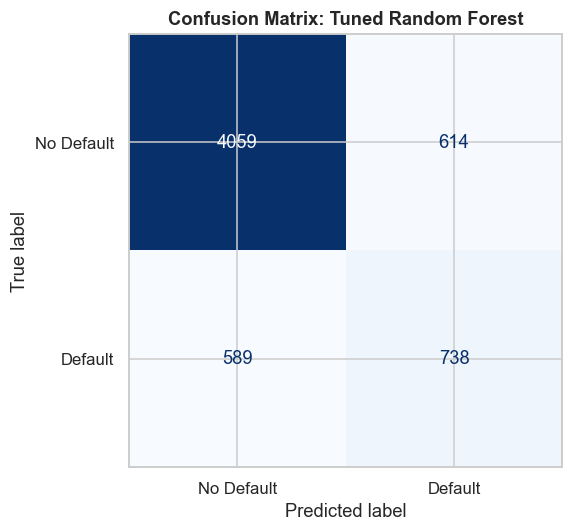

True Negatives: 4059 | False Positives: 614 | False Negatives: 589 | True Positives: 738
False negative rate (missed defaulters): 44.39%


In [58]:
best_model_name = best_row["model"]
best_models_by_name = {
    "Logistic Regression": tuned_logistic,
    "KNN": tuned_knn,
    "Decision Tree": tuned_tree,
    "Random Forest": tuned_forest,
}
final_model = best_models_by_name[best_model_name]
final_X_test = X_test
final_predictions = final_model.predict(final_X_test)

cm = confusion_matrix(yc_test, final_predictions)
fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay(cm, display_labels=["No Default", "Default"]).plot(ax=ax, cmap="Blues", colorbar=False)
ax.set_title(f"Confusion Matrix: Tuned {best_model_name}")
plt.tight_layout()
plt.show()

tn, fp, fn, tp = cm.ravel()
print(f"True Negatives: {tn} | False Positives: {fp} | False Negatives: {fn} | True Positives: {tp}")
print(f"False negative rate (missed defaulters): {fn / (fn + tp):.2%}")

# 14 · Feature Importance vs. Correlation

Compare the final Random Forest's `feature_importances_` against the raw
correlation heatmap built earlier. Agreement between the two increases
confidence in a feature's role; disagreement is worth explaining rather than
ignoring, since a feature can correlate with the target while a tree-based
model assigns it little importance once other correlated or more
informative features are already available for splitting.

In [59]:
rf_feature_names = tuned_forest.named_steps["preprocessor"].get_feature_names_out()
rf_importances = tuned_forest.named_steps["model"].feature_importances_

importance_table = pd.DataFrame({
    "feature": rf_feature_names, "importance": rf_importances,
}).sort_values("importance", ascending=False)
importance_table.head(15)

,feature,importance
11,numeric__PAY_0,0.237
12,numeric__PAY_2,0.116
13,numeric__PAY_3,0.060
9,numeric__LIMIT_BAL,0.054
14,numeric__PAY_4,0.051
20,numeric__PAY_AMT1,0.050
17,numeric__BILL_AMT1,0.048
21,numeric__PAY_AMT2,0.044
22,numeric__PAY_AMT3,0.040
18,numeric__BILL_AMT4,0.036


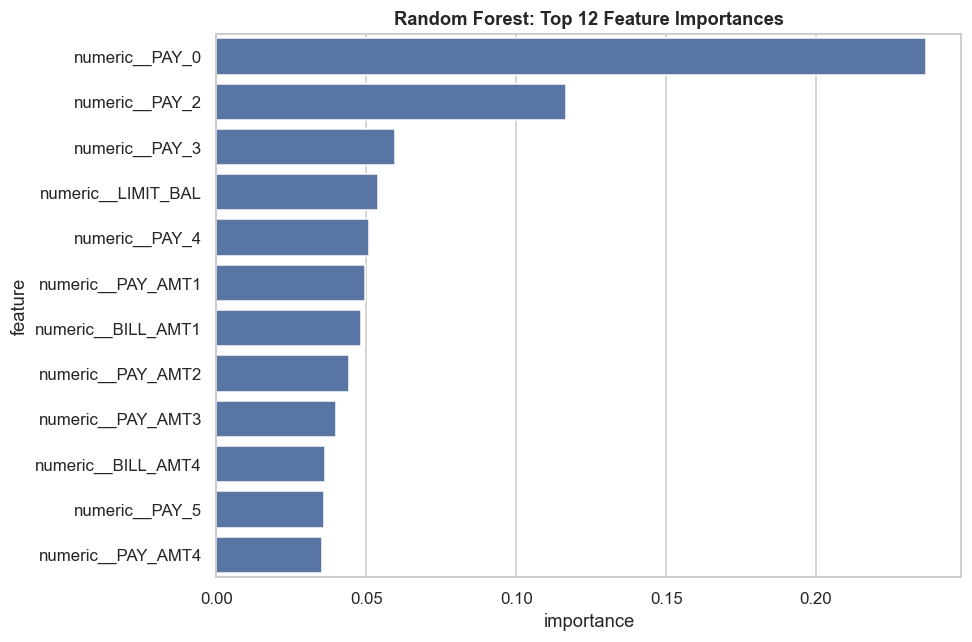

In [60]:
fig, ax = plt.subplots(figsize=(9, 6))
sns.barplot(data=importance_table.head(12), y="feature", x="importance", ax=ax)
ax.set_title("Random Forest: Top 12 Feature Importances")
plt.tight_layout()
plt.show()

In [61]:
numeric_importance = importance_table[
    importance_table["feature"].str.startswith("numeric__")
].assign(feature=lambda d: d["feature"].str.replace("numeric__", "", regex=False)).set_index("feature")["importance"]

numeric_correlation_with_target = X_clean[NUMERIC_FEATURES].corrwith(y_clean)

importance_vs_correlation = pd.DataFrame({
    "correlation_with_target": numeric_correlation_with_target,
    "rf_importance": numeric_importance,
}).sort_values("rf_importance", ascending=False)
importance_vs_correlation

,correlation_with_target,rf_importance
PAY_0,0.325,0.237
PAY_2,0.264,0.116
PAY_3,0.235,0.060
LIMIT_BAL,-0.154,0.054
PAY_4,0.217,0.051
PAY_AMT1,-0.143,0.050
BILL_AMT1,-0.029,0.048
PAY_AMT2,-0.140,0.044
PAY_AMT3,-0.125,0.040
BILL_AMT4,-0.016,0.036


Translate the best model's most heavily weighted features into concrete
recommendations for the bank's credit-risk team, grounded in the actual
feature-importance table above rather than generic industry statements.

In [62]:
top_features_text = importance_table.head(8)[["feature", "importance"]].to_dict("records")
final_report = classification_report(yc_test, final_predictions, output_dict=True, zero_division=0)
final_recall_default = final_report["1"]["recall"]
recommendation_summary_text = (
    f"Final best model: tuned {best_model_name}, test accuracy {best_row['test_accuracy']:.4f}, "
    f"test AUC {best_row['test_auc']:.4f}, recall on defaulted class {final_recall_default:.4f}. "
    f"Top 8 most important features (Random Forest): {top_features_text}. "
    f"False negative rate (missed defaulters): {fn / (fn + tp):.2%}."
)
display(Markdown(generate_insight(
    "Translate the final credit card default model's most influential features into concrete risk "
    "management and credit policy recommendations for a bank, grounded in the actual model results.",
    recommendation_summary_text,
)))

Our tuned Random Forest model achieved a test accuracy of 0.7995 and a test AUC of 0.7810, driven heavily by recent repayment history, which accounts for the vast majority of predictive power. Specifically, repayment status in the most recent month (`PAY_0`, importance 0.2366) and the preceding month (`PAY_2`, importance 0.1165) dominate risk scoring, dwarfing factors like credit limit (`LIMIT_BAL`, importance 0.0539). However, the model still misses 44.39% of defaults (False Negative Rate), meaning single-variable interventions will fail to catch systemic credit deterioration.

* **Implement Real Time Delinquency Triggers:** Because `PAY_0` and `PAY_2` are the single most critical indicators of default risk, underwriting systems should automatically freeze credit line increases or initiate conservative limit reductions the moment a borrower registers any payment delay.
* **Overhaul Behavioral Scoring Models to Address False Negatives:** Given that the model fails to catch 44.39% of defaulting accounts, risk management must recalibrate decision thresholds or integrate supplementary alternative data sources to capture hidden risk among seemingly stable borrowers.
* **Establish Dynamic Exposure Caps Linked to Payment Velocity:** Since `PAY_AMT1` and `BILL_AMT1` carry substantial weight (importances of 0.0496 and 0.0484, respectively), credit policies should dynamically adjust maximum allowable exposures based on the ratio of monthly payments to outstanding balances rather than relying solely on initial income or static credit limits.

# 16 · Conclusion

Before closing out, recap the best model's headline numbers in one place,
mirroring the running comparison table from Section 12.

In [63]:
final_summary = full_comparison[full_comparison["model"] == best_model_name][[
    "stage", "train_accuracy", "test_accuracy", "test_auc",
    "test_precision_default", "test_recall_default", "test_f1_default", "overfit_gap_pct", "verdict",
]].reset_index(drop=True)
print(f"Best model across every stage: {best_model_name}")
display(final_summary)

Best model across every stage: Random Forest


,stage,train_accuracy,test_accuracy,test_auc,test_precision_default,test_recall_default,test_f1_default,overfit_gap_pct,verdict
0,Baseline,0.999,0.816,0.764,0.650,0.366,0.468,18.333,OVERFIT
1,EDA (no imbalance),0.999,0.818,0.763,0.659,0.365,0.470,18.167,OVERFIT
2,EDA + imbalance handled,0.999,0.815,0.766,0.660,0.341,0.449,18.417,OVERFIT
3,Tuned,0.841,0.799,0.781,0.546,0.556,0.551,4.972,OK


This notebook took a genuinely untouched baseline across four classification
algorithms, Logistic Regression, KNN, a Decision Tree, and a Random Forest,
and progressively added full EDA (cleaning, encoding, scaling,
multicollinearity remediation), imbalance handling matched to each model
family (SMOTE for the distance/gradient-sensitive models, class_weight for
the tree-based ones), and GridSearchCV hyperparameter tuning, including the
gini-versus-entropy choice and cost-complexity pruning for the tree models.
Every stage was measured against the same held-out rows with the same
evaluation toolkit: accuracy, full classification report, ROC-AUC, the
overfit/underfit gap, out-of-bag score for the forest, and the winning K
for KNN. The result is a clear, evidence-backed picture of which
preprocessing and tuning decisions actually mattered, and a final model the
bank's credit-risk team can act on with the context needed to interpret it
correctly.